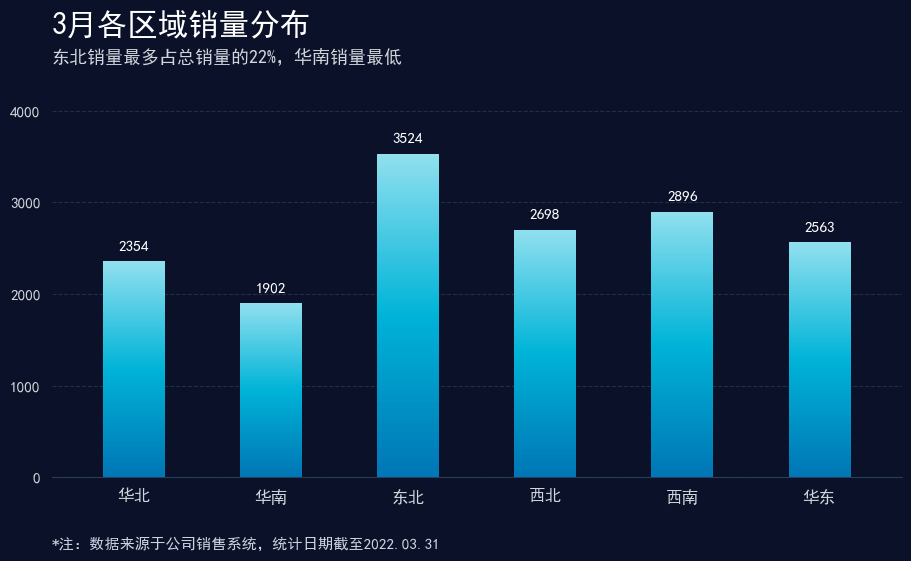

In [18]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 数据
regions = ['华北', '华南', '东北', '西北', '西南', '华东']
sales = [2354, 1902, 3524, 2698, 2896, 2563]

# 配色方案
bg_color = '#0a1128'      # 背景深色
text_light = '#d1d5db'    # 浅色文字
text_white = '#ffffff'    # 白色文字
grid_color = '#2a3b5c'    # 网格线颜色

# ✅ 恢复渐变：青蓝色渐变色带（底部深蓝 -> 顶部亮青）
cmap = LinearSegmentedColormap.from_list('grad', ['#0077b6', '#00b4d8', '#90e0ef'])

# 创建图表
fig, ax = plt.subplots(figsize=(10, 5.5))
fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)

x = np.arange(len(regions))
width = 0.45  # 柱子宽度

# ✅ 使用 imshow + clip_path 绘制渐变柱形图
for xi, yi in zip(x, sales):
    # 生成渐变矩阵
    grad = np.linspace(0, 1, 100).reshape(-1, 1)
    # 绘制渐变图并放置在对应坐标
    im = ax.imshow(grad, extent=[xi - width/2, xi + width/2, 0, yi],
                   aspect='auto', cmap=cmap, origin='lower', zorder=3)
    # 创建矩形轮廓，用来裁剪渐变图
    rect = Rectangle((xi - width/2, 0), width, yi, transform=ax.transData)
    im.set_clip_path(rect)
    
    # 柱顶外部的白色数值标签
    ax.text(xi, yi + 100, str(yi), ha='center', va='bottom', 
            color=text_white, fontsize=11, fontweight='bold', zorder=4)

# 添加主标题和副标题
ax.text(0, 1.15, '3月各区域销量分布', transform=ax.transAxes, 
        fontsize=22, fontweight='bold', color=text_white, ha='left')
ax.text(0, 1.08, '东北销量最多占总销量的22%，华南销量最低', transform=ax.transAxes, 
        fontsize=13, color=text_light, ha='left')

# ✅ 精确控制Y轴刻度，只保留千位数 (0, 1000, 2000, 3000, 4000)
ax.set_yticks([0, 1000, 2000, 3000, 4000])
ax.set_yticklabels(['0', '1000', '2000', '3000', '4000'], color=text_light, fontsize=11)

# 设置X轴样式
ax.set_xticks(x)
ax.set_xticklabels(regions, color=text_light, fontsize=12)
ax.tick_params(axis='x', length=0, pad=8)
ax.tick_params(axis='y', length=0, pad=8)

# 设置范围
ax.set_ylim(0, 4200) 
ax.set_xlim(-0.6, len(regions) - 0.4)

# 隐藏边框
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_color(grid_color)

# 优化网格线，将其放在柱子底层
ax.yaxis.grid(True, linestyle='--', color=grid_color, alpha=0.7, zorder=1)
ax.set_axisbelow(True) # 保证网格线在柱子下方

# 底部注释提亮加深
fig.text(0.1, 0.02, '*注：数据来源于公司销售系统，统计日期截至2022.03.31', 
         color='#cbd5e1', fontsize=11, fontweight='bold', ha='left')

# 调整布局
plt.subplots_adjust(top=0.85, bottom=0.15, left=0.1, right=0.95)

plt.show()

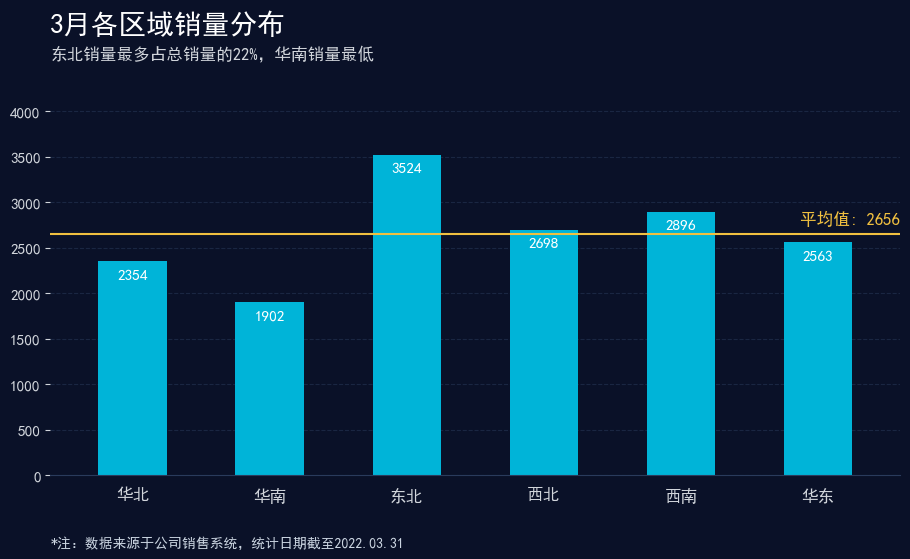

In [22]:
import matplotlib.pyplot as plt
import numpy as np

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 数据
regions = ['华北', '华南', '东北', '西北', '西南', '华东']
sales = [2354, 1902, 3524, 2698, 2896, 2563]
mean_val = np.mean(sales)  # 均值约为 2656

# 配色方案
bg_color = '#0a1128'      # 背景深色
text_light = '#d1d5db'    # 浅色文字
text_white = '#ffffff'    # 白色文字
line_color = '#f0c040'    # 均值线橙黄色
grid_color = '#2a3b5c'    # 网格线颜色
bar_color = '#00b4d8'     # 柱形图纯色

# 创建图表
fig, ax = plt.subplots(figsize=(10, 5.5))
fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)

x = np.arange(len(regions))
width = 0.5

# 绘制纯色柱形图
bars = ax.bar(x, sales, width=width, color=bar_color, zorder=2)

# ✅ 关键修改：将数值标签放入柱子内部（向下偏移 150，并垂直居中）
for bar, yi in zip(bars, sales):
    ax.text(bar.get_x() + bar.get_width()/2, yi - 150, str(yi), 
            ha='center', va='center', color=text_white, 
            fontsize=11, fontweight='bold', zorder=3)

# 均值线（橙黄色实线）
ax.axhline(mean_val, color=line_color, linestyle='-', linewidth=1.5, zorder=4)

# ✅ 关键修改：将“平均值”文字移到图表右上角，紧贴均值线之上
# 放在最后一个柱子右侧 (len(regions)-0.4)，抬高 80，右对齐
ax.text(len(regions) - 0.4, mean_val + 80, f'平均值: {int(mean_val)}', 
        color=line_color, fontsize=12, fontweight='bold', 
        ha='right', va='bottom', zorder=5)

# 添加主标题和副标题
ax.text(0, 1.15, '3月各区域销量分布', transform=ax.transAxes, 
        fontsize=20, fontweight='bold', color=text_white, ha='left')
ax.text(0, 1.08, '东北销量最多占总销量的22%，华南销量最低', transform=ax.transAxes, 
        fontsize=12, color=text_light, ha='left')

# 设置坐标轴样式
ax.set_xticks(x)
ax.set_xticklabels(regions, color=text_light, fontsize=12)
ax.tick_params(axis='x', length=0, pad=8) 
ax.tick_params(axis='y', colors=text_light, labelsize=11)

# Y轴范围稍微调高，给顶部留出空间
ax.set_ylim(0, max(sales) * 1.2) 
ax.set_xlim(-0.6, len(regions) - 0.4)

# 隐藏边框
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_color(grid_color)
ax.set_ylabel('')

# 添加水平虚线网格
ax.yaxis.grid(True, linestyle='--', color=grid_color, alpha=0.5, zorder=1)

# 底部注释（颜色提亮加深）
fig.text(0.1, 0.02, '*注：数据来源于公司销售系统，统计日期截至2022.03.31', 
         color='#cbd5e1', fontsize=10, fontweight='bold', ha='left')

# 调整布局
plt.subplots_adjust(top=0.85, bottom=0.15, left=0.1, right=0.95)

plt.show()

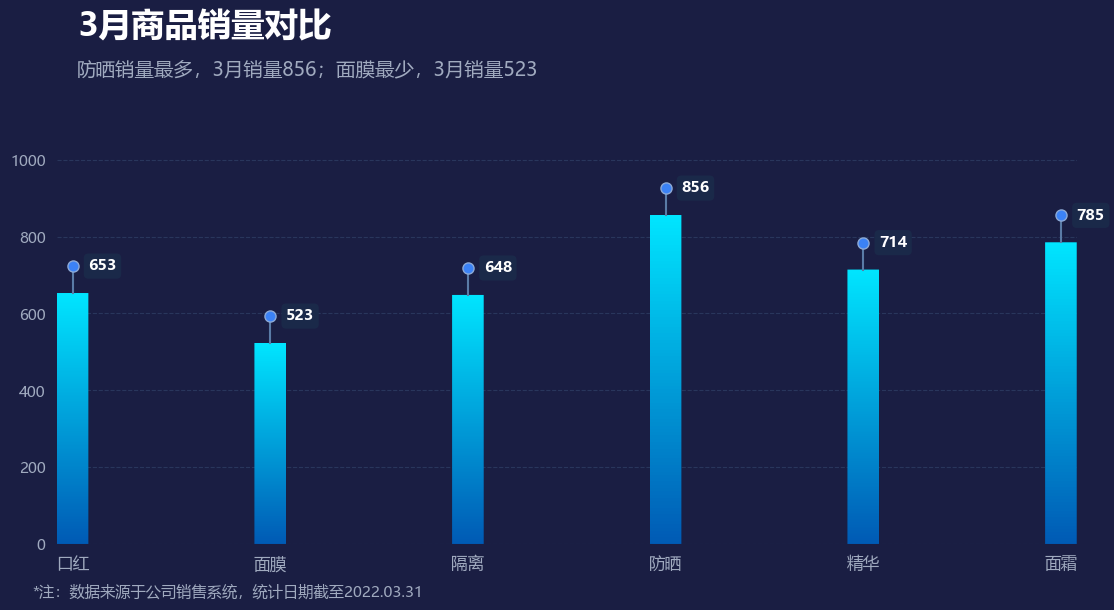

In [6]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import FancyBboxPatch

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 1. 准备数据
items = ['口红', '面膜', '隔离', '防晒', '精华', '面霜']
sales = [653, 523, 648, 856, 714, 785]
x = np.arange(len(items))
width = 0.16  # 柱子宽度

# 2. 颜色配置
bg_color = '#1A1E43'       # 背景色
text_white = '#FFFFFF'      # 标题白色
text_light = '#A0AABF'      # 副标题和刻度浅灰
grid_color = '#2E3D63'      # 网格线颜色
line_color = '#5A7BA6'      # 引出线颜色
dot_color = '#3B82F6'       # 顶部小圆点颜色
label_bg = '#1A2A4A'        # 数据标签背景框颜色

# 柱子渐变颜色（底部深蓝 -> 顶部亮青）
cmap = LinearSegmentedColormap.from_list('grad', ['#005bb5', '#00e5ff'])

# 3. 创建画布
fig, ax = plt.subplots(figsize=(12, 6.5))
fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)

# 4. 绘制上下圆角柱形图（核心修复：使用 FancyBboxPatch 上下圆角）
for xi, yi in zip(x, sales):
    # 生成渐变矩阵
    grad = np.linspace(0, 1, 100).reshape(-1, 1)
    # 绘制渐变图
    im = ax.imshow(grad, extent=[xi - width/2, xi + width/2, 0, yi],
                   aspect='auto', cmap=cmap, origin='lower', zorder=3)
    
    # ✅ 使用圆角矩形，rounding_size 为 width/2，实现上下两端的半圆效果
    box = FancyBboxPatch((xi - width/2, 0), width, yi,
                         boxstyle=f"round,pad=0,rounding_size={width/2}",
                         transform=ax.transData, facecolor='none', edgecolor='none')
    ax.add_patch(box)
    im.set_clip_path(box)

# 5. 绘制引出线、圆点和数据标签
offset_y = 70  # 线条长度
for xi, yi in zip(x, sales):
    dot_y = yi + offset_y
    
    # 引出线（从柱子顶端最高处 yi 向上延伸）
    ax.plot([xi, xi], [yi, dot_y], color=line_color, linewidth=1.5, zorder=4)
    
    # 顶部小圆点
    ax.plot(xi, dot_y, marker='o', markersize=8, 
            color=dot_color, markeredgecolor='#8CA9D6', markeredgewidth=1, zorder=5)
    
    # 右侧数据标签（带深色背景框）
    ax.text(xi + 0.08, dot_y, str(yi), 
            ha='left', va='center', 
            color=text_white, fontsize=11, fontweight='bold',
            bbox=dict(boxstyle="round,pad=0.3", fc=label_bg, ec="none", alpha=0.95),
            zorder=6)

# 6. 添加标题、副标题和底部注释
ax.text(0.02, 1.15, '3月商品销量对比', transform=ax.transAxes, 
        color=text_white, fontsize=24, fontweight='bold', ha='left')
ax.text(0.02, 1.06, '防晒销量最多，3月销量856；面膜最少，3月销量523', transform=ax.transAxes, 
        color=text_light, fontsize=14, ha='left')

fig.text(0.08, 0.04, '*注：数据来源于公司销售系统，统计日期截至2022.03.31', 
         color=text_light, fontsize=11, ha='left')

# 7. 配置坐标轴格式
# 设置Y轴刻度和范围
ax.set_yticks([0, 200, 400, 600, 800, 1000, 1200])
ax.set_yticklabels(['0', '200', '400', '600', '800', '1000', '1200'], 
                   color=text_light, fontsize=11)
# ✅ 关键修复：Y轴下限设为 -width/2，让柱子底部的半圆能完整显示，不被截断
ax.set_ylim(-width/2, 1150)

# 设置X轴标签
ax.set_xticks(x)
ax.set_xticklabels(items, color=text_light, fontsize=12)

# 隐藏四周边框
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

# 隐藏刻度线
ax.tick_params(axis='x', length=0, pad=8) 
ax.tick_params(axis='y', length=0, pad=8) 

# 添加水平虚线网格（放在柱子底层）
ax.yaxis.grid(True, linestyle='--', color=grid_color, alpha=0.8, zorder=1)
ax.set_axisbelow(True)

# 8. 调整布局并显示
plt.subplots_adjust(top=0.8, bottom=0.12, left=0.1, right=0.95)
plt.show()

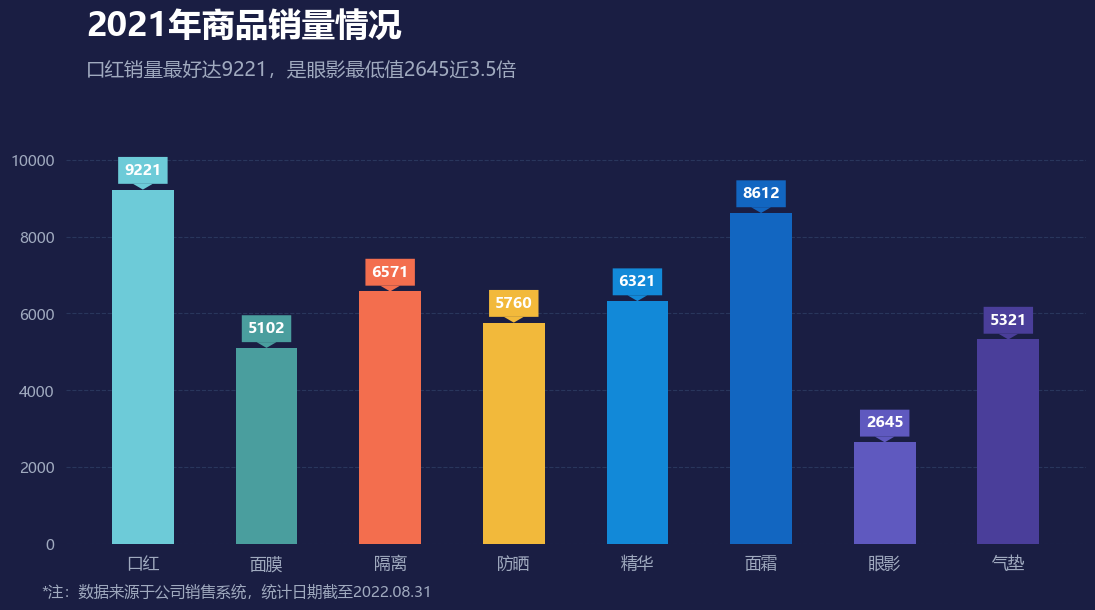

In [10]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import FancyBboxPatch, Polygon

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 1. 准备数据
items = ['口红', '面膜', '隔离', '防晒', '精华', '面霜', '眼影', '气垫']
sales = [9221, 5102, 6571, 5760, 6321, 8612, 2645, 5321]

# 2. 颜色配置
colors = [
    '#6dcbd8', '#4a9e9e', '#f36e4e', '#f2b93b',
    '#1289d8', '#1266c1', '#5f59bf', '#4a3e9a'
]

x = np.arange(len(items))
width = 0.5

# 3. 创建画布
bg_color = '#1A1E43'
text_white = '#FFFFFF'
text_light = '#A0AABF'
grid_color = '#2E3D63'

fig, ax = plt.subplots(figsize=(12, 6.5))
fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)

# 4. 绘制纯色柱形图
bars = ax.bar(x, sales, width=width, color=colors, zorder=3)

# 5. ✅ 核心修改：绘制带向下小三角的数据标签（精准控制尺寸，避免覆盖图形）
for i, (xi, yi) in enumerate(zip(x, sales)):
    # 气泡框的尺寸（按照正常视觉比例设定，避免太大）
    box_width = 0.4   # 框宽
    box_height = 700  # 框高
    tri_width = 0.16  # 三角形宽
    tri_height = 150  # 三角形高
    
    box_color = colors[i]
    
    # 1. 绘制圆角矩形背景（下沿距离柱顶 150 的高度）
    rect = FancyBboxPatch((xi - box_width/2, yi + tri_height), box_width, box_height,
                          boxstyle="round,pad=0,rounding_size=0.05", # 小圆角
                          facecolor=box_color, edgecolor='none', zorder=4)
    ax.add_patch(rect)
    
    # 2. 绘制向下的小三角形（尖端刚好指向柱子顶部）
    triangle = Polygon([
        [xi - tri_width/2, yi + tri_height],  # 左底角
        [xi + tri_width/2, yi + tri_height],  # 右底角
        [xi, yi]                              # 尖端
    ], facecolor=box_color, edgecolor='none', zorder=4)
    ax.add_patch(triangle)
    
    # 3. 绘制数字文本（在圆角矩形的中心）
    ax.text(xi, yi + tri_height + box_height/2, str(yi), 
            ha='center', va='center', 
            color=text_white, fontsize=11, fontweight='bold', zorder=5)

# 6. 添加标题、副标题和底部注释
ax.text(0.02, 1.15, '2021年商品销量情况', transform=ax.transAxes, 
        color=text_white, fontsize=24, fontweight='bold', ha='left')
ax.text(0.02, 1.06, '口红销量最好达9221，是眼影最低值2645近3.5倍', transform=ax.transAxes, 
        color=text_light, fontsize=14, ha='left')

fig.text(0.08, 0.04, '*注：数据来源于公司销售系统，统计日期截至2022.08.31', 
         color=text_light, fontsize=11, ha='left')

# 7. 配置坐标轴格式
ax.set_yticks([0, 2000, 4000, 6000, 8000, 10000])
ax.set_yticklabels(['0', '2000', '4000', '6000', '8000', '10000'], 
                   color=text_light, fontsize=11)
ax.set_ylim(0, 11500)

ax.set_xticks(x)
ax.set_xticklabels(items, color=text_light, fontsize=12)

# 隐藏四周边框
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

# 隐藏刻度线
ax.tick_params(axis='x', length=0, pad=8) 
ax.tick_params(axis='y', length=0, pad=8) 

# 添加水平虚线网格
ax.yaxis.grid(True, linestyle='--', color=grid_color, alpha=0.8, zorder=1)
ax.set_axisbelow(True)

# 8. 调整布局并显示
plt.subplots_adjust(top=0.8, bottom=0.12, left=0.1, right=0.95)
plt.show()

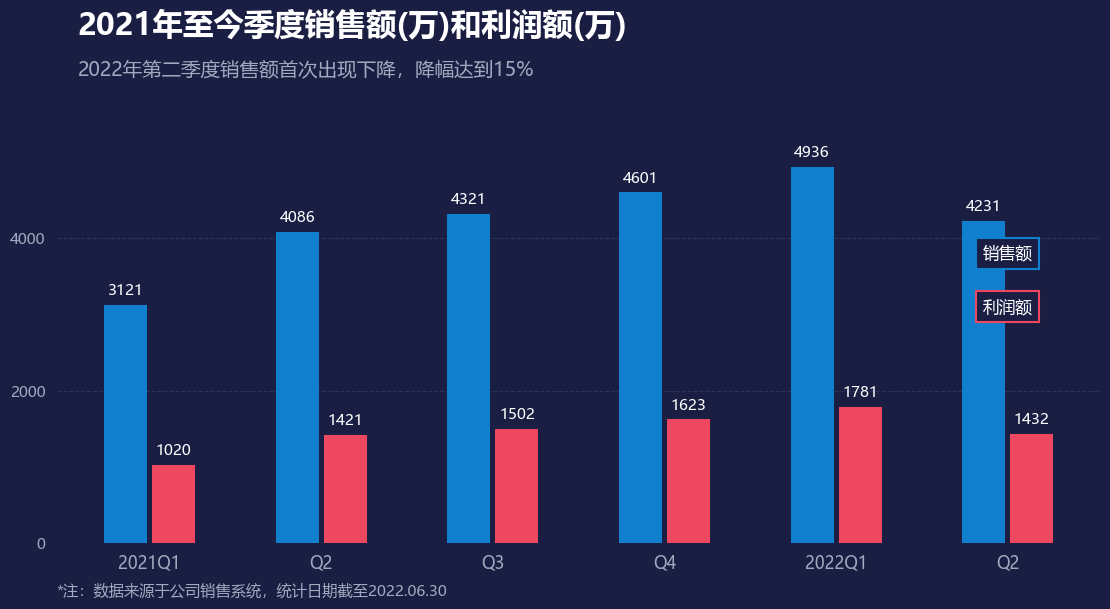

In [18]:
import matplotlib.pyplot as plt
import numpy as np

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 1. 准备数据
quarters = ['2021Q1', 'Q2', 'Q3', 'Q4', '2022Q1', 'Q2']
sales = [3121, 4086, 4321, 4601, 4936, 4231]
profit = [1020, 1421, 1502, 1623, 1781, 1432]

x = np.arange(len(quarters))

# ✅ 修改点1：缩小柱宽并拉大偏移量，防止柱子粘连
width = 0.25
offset = 0.14

# 2. 颜色配置
bg_color = '#1A1E43'       # 背景色
text_white = '#FFFFFF'      # 白色文字
text_light = '#A0AABF'      # 浅灰文字
grid_color = '#2E3D63'      # 网格线颜色
sales_color = '#0F7FCE'     # 销售额蓝色
profit_color = '#EE4760'    # 利润额红色

# 3. 创建画布
fig, ax = plt.subplots(figsize=(12, 6.5))
fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)

# 4. 绘制分组柱形图
# 销售额柱子（左）
bars1 = ax.bar(x - offset, sales, width, color=sales_color, zorder=3)
# 利润额柱子（右）
bars2 = ax.bar(x + offset, profit, width, color=profit_color, zorder=3)

# 5. 添加数据标签（纯白数字）
for bar, yi in zip(bars1, sales):
    ax.text(bar.get_x() + bar.get_width()/2, yi + 80, str(yi), 
            ha='center', va='bottom', color=text_white, fontsize=11, zorder=5)
for bar, yi in zip(bars2, profit):
    ax.text(bar.get_x() + bar.get_width()/2, yi + 80, str(yi), 
            ha='center', va='bottom', color=text_white, fontsize=11, zorder=5)

# 6. ✅ 修改点2：图例精准叠在最后一组柱子上
# 最后一组柱子的 x 坐标是 5（即 2022Q2）
legend_x = 5
legend_y1 = 3800 # 销售额图例高度
legend_y2 = 3100 # 利润额图例高度

# 绘制带蓝色边框的“销售额”图例（带深色背景框，zorder=10 保证盖在柱子上）
ax.text(legend_x, legend_y1, '销售额', ha='center', va='center',
        color=text_white, fontsize=12,
        bbox=dict(boxstyle="square,pad=0.4", facecolor=bg_color, edgecolor=sales_color, linewidth=1.5),
        zorder=10)

# 绘制带红色边框的“利润额”图例
ax.text(legend_x, legend_y2, '利润额', ha='center', va='center',
        color=text_white, fontsize=12,
        bbox=dict(boxstyle="square,pad=0.4", facecolor=bg_color, edgecolor=profit_color, linewidth=1.5),
        zorder=10)

# 7. 添加标题、副标题和底部注释
ax.text(0.02, 1.15, '2021年至今季度销售额(万)和利润额(万)', transform=ax.transAxes, 
        color=text_white, fontsize=22, fontweight='bold', ha='left')
ax.text(0.02, 1.06, '2022年第二季度销售额首次出现下降，降幅达到15%', transform=ax.transAxes, 
        color=text_light, fontsize=14, ha='left')

fig.text(0.08, 0.04, '*注：数据来源于公司销售系统，统计日期截至2022.06.30', 
         color=text_light, fontsize=11, ha='left')

# 8. 配置坐标轴格式
ax.set_yticks([0, 2000, 4000, 6000])
ax.set_yticklabels(['0', '2000', '4000', '6000'], 
                   color=text_light, fontsize=11)
ax.set_ylim(0, 5800) 

ax.set_xticks(x)
ax.set_xticklabels(quarters, color=text_light, fontsize=12)

# 隐藏四周边框
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

# 隐藏刻度线
ax.tick_params(axis='x', length=0, pad=8) 
ax.tick_params(axis='y', length=0, pad=8) 

# 添加水平虚线网格
ax.yaxis.grid(True, linestyle='--', color=grid_color, alpha=0.8, zorder=1)
ax.set_axisbelow(True)

# 9. 调整布局并显示
plt.subplots_adjust(top=0.8, bottom=0.12, left=0.08, right=0.95)
plt.show()

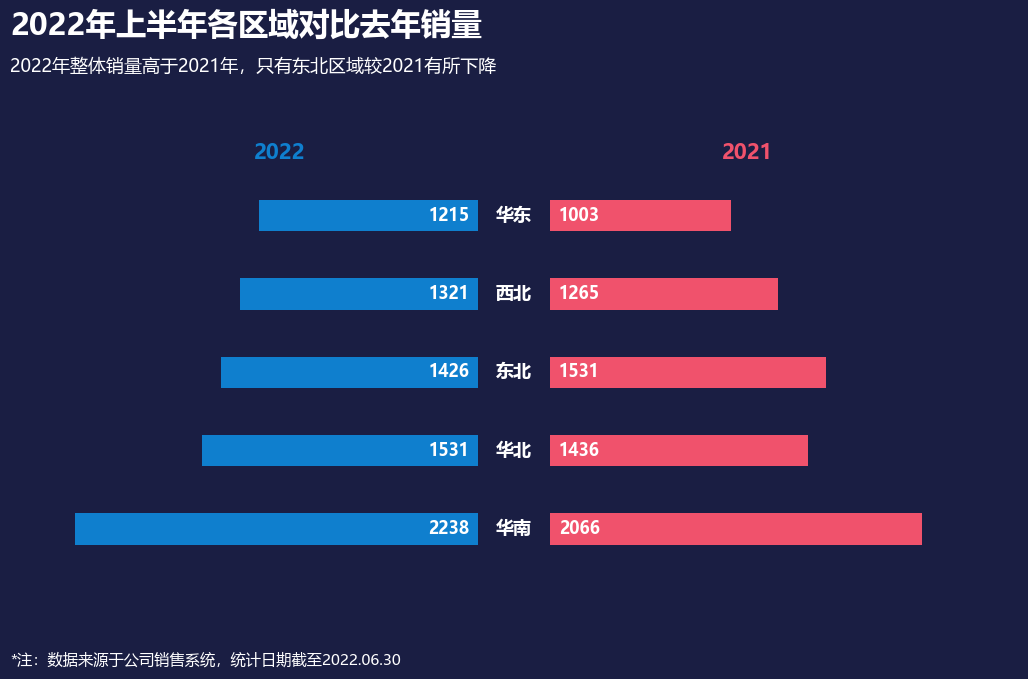

In [24]:
import matplotlib.pyplot as plt
import numpy as np

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 1. 准备数据（严格按原图从上到下的顺序）
regions = ['华南', '华北', '东北', '西北', '华东']
sales_2022 = [2238, 1531, 1426, 1321, 1215]  # 左侧 2022 数据
sales_2021 = [2066, 1436, 1531, 1265, 1003]  # 右侧 2021 数据

# 2. 坐标轴与颜色配置
y = np.arange(len(regions))
height = 0.4  # 柱子高度

bg_color = '#1A1E43'        # 背景色
text_white = '#FFFFFF'      # 白色文字
color_2022 = '#0F7FCE'      # 2022年蓝色
color_2021 = '#F0526C'      # 2021年红色

# 3. 创建画布
fig, ax = plt.subplots(figsize=(12, 7))
fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)

# 4. 绘制蝴蝶图
ax.barh(y, [-v for v in sales_2022], height=height, left=-200, 
        color=color_2022, edgecolor='none', zorder=3)
ax.barh(y, sales_2021, height=height, left=200, 
        color=color_2021, edgecolor='none', zorder=3)

# 5. 添加数据标签和区域名称
for i in range(len(regions)):
    ax.text(-250, y[i], str(sales_2022[i]), ha='right', va='center', 
            color=text_white, fontsize=12, fontweight='bold', zorder=5)
    ax.text(250, y[i], str(sales_2021[i]), ha='left', va='center', 
            color=text_white, fontsize=12, fontweight='bold', zorder=5)
    ax.text(0, y[i], regions[i], ha='center', va='center', 
            color=text_white, fontsize=13, fontweight='bold', zorder=6)

# 6. ✅ 修改点：将年份标签移到最上方
# 放在华南（y=4）的上方，y坐标改为 4.8
ax.text(-1300, 4.8, '2022', ha='center', va='center', 
        color=color_2022, fontsize=15, fontweight='bold', zorder=5)
ax.text(1300, 4.8, '2021', ha='center', va='center', 
        color=color_2021, fontsize=15, fontweight='bold', zorder=5)

# 7. 添加标题、副标题和底部注释（严格左对齐）
ax.text(0.0, 1.12, '2022年上半年各区域对比去年销量', transform=ax.transAxes, 
        color=text_white, fontsize=22, fontweight='bold', ha='left')
ax.text(0.0, 1.05, '2022年整体销量高于2021年，只有东北区域较2021有所下降', transform=ax.transAxes, 
        color=text_white, fontsize=13, ha='left')

fig.text(0.08, 0.04, '*注：数据来源于公司销售系统，统计日期截至2022.06.30', 
         color=text_white, fontsize=11, ha='left')

# 8. 配置坐标轴格式
ax.set_xlim(-2800, 2800) 
# ✅ 修改点：Y轴上限从 4.5 调到 5.5，给顶部的 2022/2021 留出空间
ax.set_ylim(-1.2, 5.5) 

# 隐藏刻度与边框
ax.set_xticks([])
ax.set_yticks([])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

# 9. 调整布局并显示
plt.subplots_adjust(top=0.85, bottom=0.1, left=0.08, right=0.92)
plt.show()

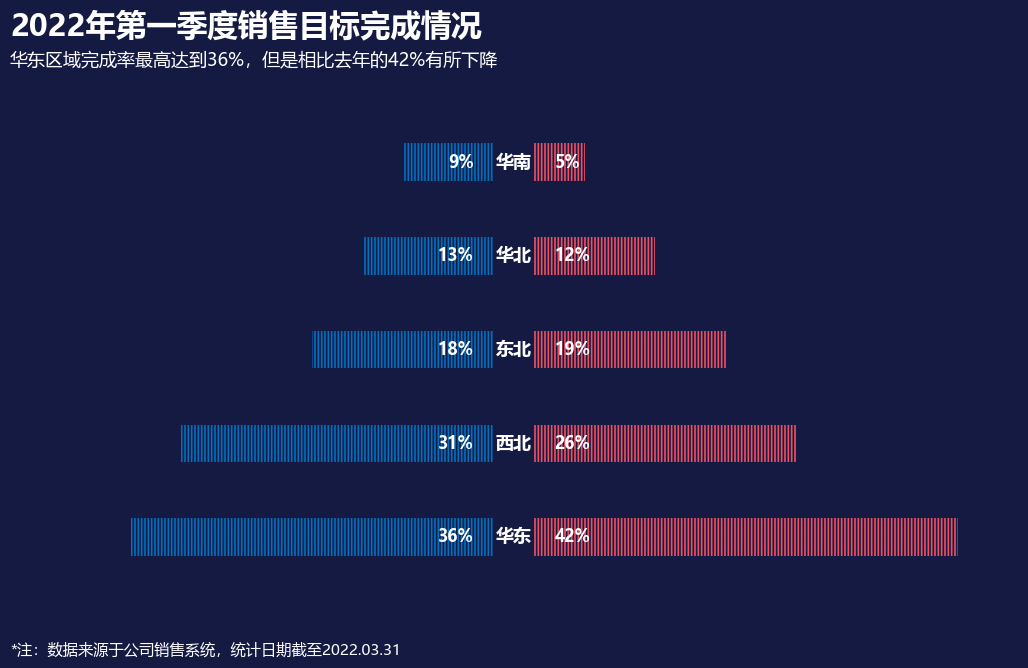

In [35]:
import matplotlib.pyplot as plt
import numpy as np

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False
# ✅ 关键设置：调整纹理线条的粗细，使其接近原图的密度
plt.rcParams['hatch.linewidth'] = 1.2

# 1. 准备数据（从上到下：华东、西北、东北、华北、华南）
regions = ['华东', '西北', '东北', '华北', '华南']
sales_2022 = [36, 31, 18, 13, 9]    # 2022年百分比
sales_2021 = [42, 26, 19, 12, 5]    # 2021年百分比

y = np.arange(len(regions))
height = 0.4  # 数据条高度

# 2. 颜色配置
bg_color = '#141A42'        # 深藏青色背景
text_white = '#FFFFFF'      # 白色文字
color_2022 = '#0070C0'      # 2022年蓝色
color_2021 = '#F05060'      # 2021年红色

# 3. 创建画布
fig, ax = plt.subplots(figsize=(12, 7))
fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)

# 4. ✅ 绘制核心的“条形码”数据条（使用 hatch 生成垂直线，无填充色）
# 左侧 2022 数据条：从中心向左延伸，left=-2 表示起点，宽度为负值
ax.barh(y, [-v for v in sales_2022], left=-2, height=height, 
        facecolor='none', edgecolor=color_2022, hatch='|||||', linewidth=0, zorder=3)
# 右侧 2021 数据条：从中心向右延伸，left=2 表示起点，宽度为正值
ax.barh(y, sales_2021, left=2, height=height, 
        facecolor='none', edgecolor=color_2021, hatch='|||||', linewidth=0, zorder=3)

# 5. 添加数据标签和区域名称
for i in range(len(regions)):
    # 左侧数字：紧贴中心间隙的左边
    ax.text(-4, y[i], f'{sales_2022[i]}%', ha='right', va='center', 
            color=text_white, fontsize=12, fontweight='bold', zorder=5)
    # 右侧数字：紧贴中心间隙的右边
    ax.text(4, y[i], f'{sales_2021[i]}%', ha='left', va='center', 
            color=text_white, fontsize=12, fontweight='bold', zorder=5)
    
    # 中心区域名称：精准居中
    ax.text(0, y[i], regions[i], ha='center', va='center', 
            color=text_white, fontsize=13, fontweight='bold', zorder=6)

# 6. 添加标题、副标题和底部注释（严格左对齐，统一白色）
ax.text(0.0, 1.10, '2022年第一季度销售目标完成情况', transform=ax.transAxes, 
        color=text_white, fontsize=22, fontweight='bold', ha='left')
ax.text(0.0, 1.04, '华东区域完成率最高达到36%，但是相比去年的42%有所下降', transform=ax.transAxes, 
        color=text_white, fontsize=13, ha='left')

fig.text(0.08, 0.04, '*注：数据来源于公司销售系统，统计日期截至2022.03.31', 
         color=text_white, fontsize=11, ha='left')

# 7. 配置坐标轴格式
# 设置X轴范围，左侧留出空间，右侧留出空间
ax.set_xlim(-50, 50)
# 设置Y轴范围，留出上下空间
ax.set_ylim(-0.8, len(regions) - 0.2)

# 隐藏刻度与边框
ax.set_xticks([])
ax.set_yticks([])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

# 8. 调整布局并显示
plt.subplots_adjust(top=0.85, bottom=0.1, left=0.08, right=0.92)
plt.show()

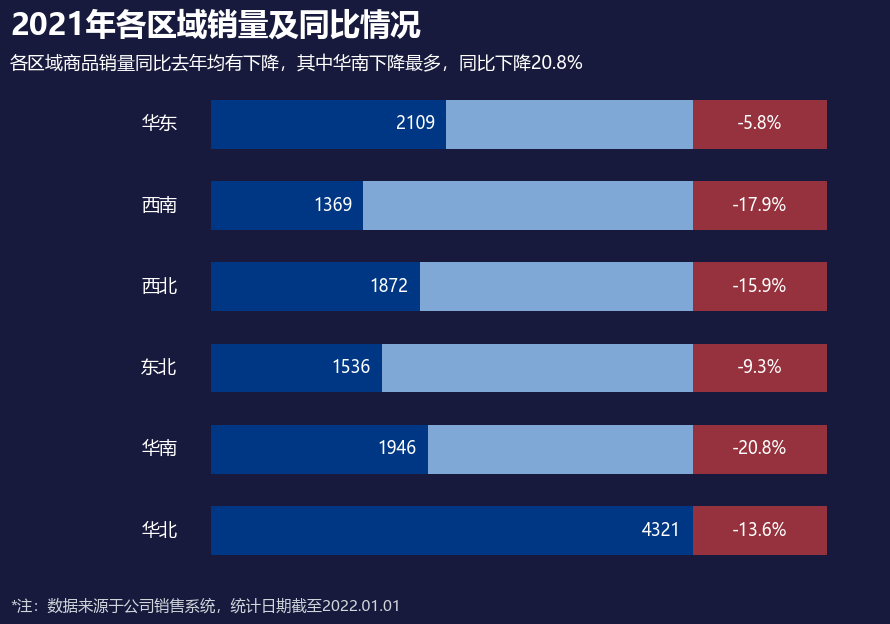

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 1. 准备数据（从上到下）
regions = ['华东', '西南', '西北', '东北', '华南', '华北']
sales = [2109, 1369, 1872, 1536, 1946, 4321]
yoy = ['-5.8%', '-17.9%', '-15.9%', '-9.3%', '-20.8%', '-13.6%']

max_sales = max(sales) # 4321

# 2. 颜色配置
bg_color = '#171a3c'        # 背景色
color_dark_blue = '#003785' # 深蓝色（销量）
color_light_blue = '#7fa8d6'# 浅蓝色（占位）
color_red = '#96323e'       # 红色（同比）
text_white = '#ffffff'      # 白色文字
text_light = '#d1d5db'      # 浅灰文字

# 3. 创建画布
fig, ax = plt.subplots(figsize=(10, 6.5))
fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)

y_pos = np.arange(len(regions))
height = 0.6

# 设定红色块的固定宽度
red_width = 1200

# 4. 循环绘制每一行的条形图
for i, (region, s, y_val) in enumerate(zip(regions, sales, yoy)):
    # 绘制深蓝色块
    w1 = s
    ax.barh(y_pos[i], w1, height=height, left=0, color=color_dark_blue, zorder=3)
    
    # 绘制浅蓝色块（如果没达到最大销量，就用浅蓝填补差值）
    w2 = max_sales - w1
    if w2 > 0:
        ax.barh(y_pos[i], w2, height=height, left=w1, color=color_light_blue, zorder=3)
        
    # 绘制固定宽度的红色块
    ax.barh(y_pos[i], red_width, height=height, left=max_sales, color=color_red, zorder=3)
    
    # 添加销量数字（在深蓝块内部靠右）
    ax.text(w1 - 100, y_pos[i], str(s), ha='right', va='center', color=text_white, fontsize=12, zorder=4)
    
    # 添加同比百分比（在红色块正中心）
    ax.text(max_sales + red_width/2, y_pos[i], y_val, ha='center', va='center', color=text_white, fontsize=12, zorder=4)
    
    # 添加左侧区域名称
    ax.text(-300, y_pos[i], region, ha='right', va='center', color=text_white, fontsize=13, zorder=4)

# 反转Y轴，让“华东”显示在最上面
ax.invert_yaxis()

# 5. 添加标题、副标题和底部注释（严格左对齐）
ax.text(0.0, 1.10, '2021年各区域销量及同比情况', transform=ax.transAxes, 
        color=text_white, fontsize=22, fontweight='bold', ha='left')
ax.text(0.0, 1.03, '各区域商品销量同比去年均有下降，其中华南下降最多，同比下降20.8%', transform=ax.transAxes, 
        color=text_white, fontsize=13, ha='left')

fig.text(0.08, 0.04, '*注：数据来源于公司销售系统，统计日期截至2022.01.01', 
         color=text_light, fontsize=11, ha='left')

# 6. 配置坐标轴格式
ax.set_xlim(-1800, 6000)
ax.set_ylim(len(regions) - 0.5, -0.5) 

# 隐藏所有边框和刻度
ax.axis('off')

# 7. 调整布局并显示
plt.subplots_adjust(top=0.85, bottom=0.1, left=0.08, right=0.95)
plt.show()

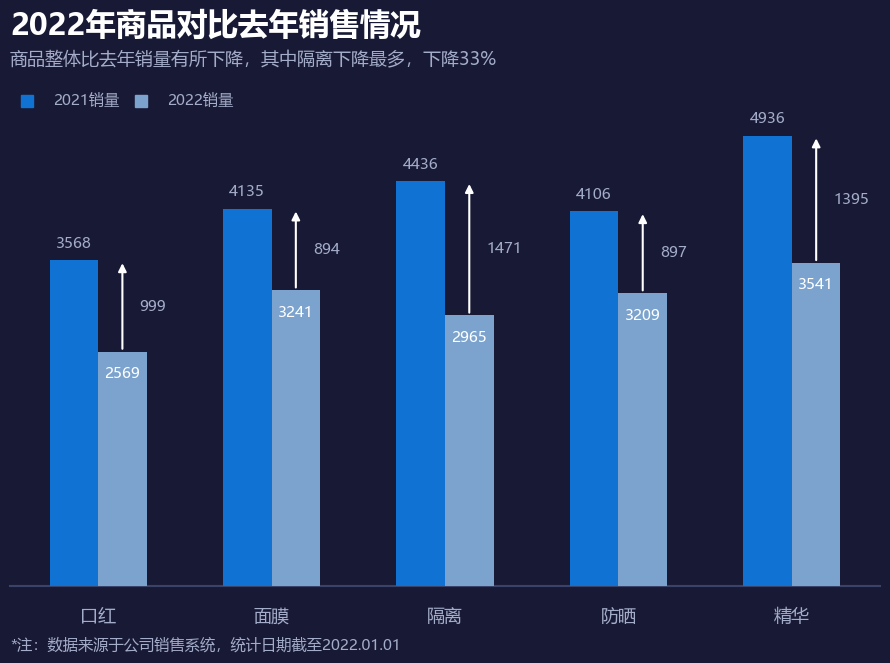

In [2]:
import matplotlib.pyplot as plt
import numpy as np

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 1. 准备数据
goods = ['口红', '面膜', '隔离', '防晒', '精华']
sales_2021 = [3568, 4135, 4436, 4106, 4936]
sales_2022 = [2569, 3241, 2965, 3209, 3541]
diff = [a - b for a, b in zip(sales_2021, sales_2022)]  # 计算差值

x = np.arange(len(goods))
width = 0.28  # 柱子宽度

# 2. 颜色与样式配置
bg_color = '#181a35'        # 背景色
color_2021 = '#1072d2'      # 2021年深蓝色
color_2022 = '#7ba3ce'      # 2022年浅灰蓝色
text_white = '#ffffff'      # 白色文字
text_light = '#a3acc8'      # 浅灰文字
grid_color = '#3b4268'      # X轴底线颜色

# 3. 创建画布
fig, ax = plt.subplots(figsize=(10, 7))
fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)

# 4. 绘制双柱状图
bars_2021 = ax.bar(x - width/2, sales_2021, width, color=color_2021, zorder=3)
bars_2022 = ax.bar(x + width/2, sales_2022, width, color=color_2022, zorder=3)

# 5. 添加数据标签和差值箭头
for i in range(len(goods)):
    # 2021年顶部标签（浅灰色）
    ax.text(x[i] - width/2, sales_2021[i] + 100, str(sales_2021[i]), 
            ha='center', va='bottom', color=text_light, fontsize=11, zorder=4)
    
    # 2022年内部/顶部标签（原图中数字在浅色柱子内部上方）
    ax.text(x[i] + width/2, sales_2022[i] - 150, str(sales_2022[i]), 
            ha='center', va='top', color=text_white, fontsize=11, zorder=4)
    
    # ✅ 绘制带箭头的垂直差值标注
    # 箭头的起点：2022柱子顶部，终点：2021柱子顶部高度
    ax.annotate('', 
                xy=(x[i] + width/2, sales_2021[i]),      # 箭头指向
                xytext=(x[i] + width/2, sales_2022[i]),  # 箭头起点
                arrowprops=dict(arrowstyle="-|>", color="white", lw=1.5, mutation_scale=12),
                zorder=5)
    
    # 差值数字（放在箭头右侧，高度取两柱的中间偏上位置）
    mid_y = sales_2022[i] + (sales_2021[i] - sales_2022[i]) / 2
    ax.text(x[i] + width/2 + 0.1, mid_y, str(diff[i]), 
            ha='left', va='center', color=text_light, fontsize=11, zorder=5)

# 6. 自定义图例（左上角手动绘制方块和文字）
# 画 2021 图例
ax.plot(0.02, 0.95, marker='s', markersize=8, color=color_2021, transform=ax.transAxes)
ax.text(0.05, 0.95, '2021销量', ha='left', va='center', color=text_light, fontsize=11, transform=ax.transAxes)

# 画 2022 图例
ax.plot(0.15, 0.95, marker='s', markersize=8, color=color_2022, transform=ax.transAxes)
ax.text(0.18, 0.95, '2022销量', ha='left', va='center', color=text_light, fontsize=11, transform=ax.transAxes)

# 7. 添加标题、副标题和底部注释（严格左对齐）
ax.text(0.0, 1.08, '2022年商品对比去年销售情况', transform=ax.transAxes, 
        color=text_white, fontsize=22, fontweight='bold', ha='left')
ax.text(0.0, 1.02, '商品整体比去年销量有所下降，其中隔离下降最多，下降33%', transform=ax.transAxes, 
        color=text_light, fontsize=13, ha='left')

fig.text(0.08, 0.03, '*注：数据来源于公司销售系统，统计日期截至2022.01.01', 
         color=text_light, fontsize=11, ha='left')

# 8. 配置坐标轴格式
ax.set_ylim(0, 5600)  # 留出顶部空间
ax.set_xticks(x)
ax.set_xticklabels(goods, color=text_light, fontsize=13)
ax.tick_params(axis='x', length=0, pad=15) # 隐藏刻度线，拉开与轴线的距离

# 隐藏Y轴刻度
ax.set_yticks([])

# 隐藏顶部、右侧、左侧边框，只保留底部底边线
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(True)
ax.spines['bottom'].set_color(grid_color)
ax.spines['bottom'].set_linewidth(1.5)

# 9. 调整布局并显示
plt.subplots_adjust(top=0.85, bottom=0.12, left=0.08, right=0.95)
plt.show()

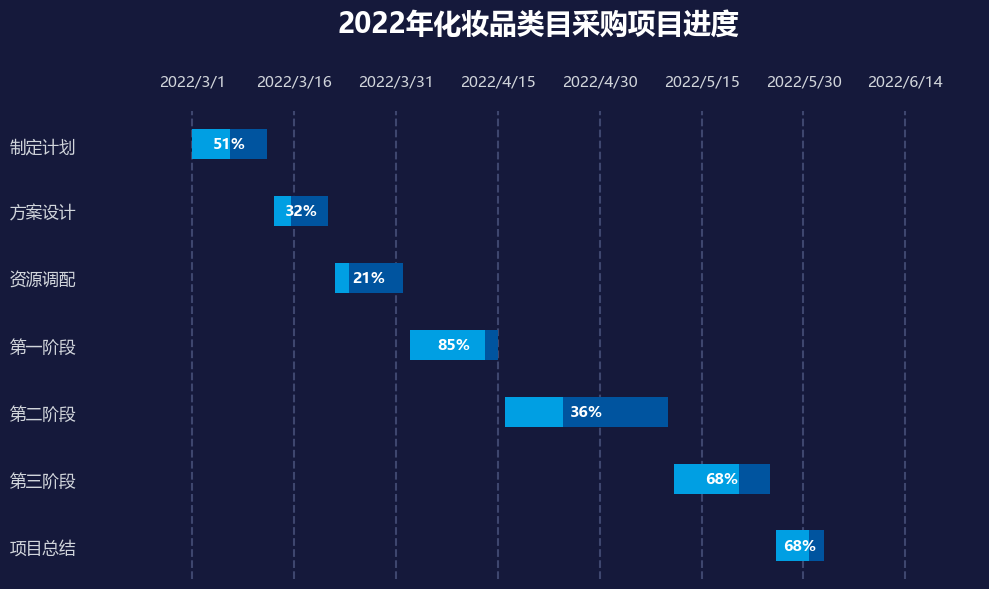

In [4]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime
import numpy as np

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 1. 准备数据
tasks = ['制定计划', '方案设计', '资源调配', '第一阶段', '第二阶段', '第三阶段', '项目总结']
start_dates = ['2022-03-01', '2022-03-13', '2022-03-22', '2022-04-02', '2022-04-16', '2022-05-11', '2022-05-26']
durations = [11, 8, 10, 13, 24, 14, 7]
percentages = [51, 32, 21, 85, 36, 68, 68]

# 转换日期格式
start_dts = [datetime.strptime(d, '%Y-%m-%d') for d in start_dates]
start_nums = [mdates.date2num(d) for d in start_dts]

# 2. 颜色配置
bg_color = '#15193B'        # 背景色
color_dark_blue = '#00549F' # 深蓝色（代表未完成/总周期）
color_light_blue = '#009FE3'# 亮蓝色（代表已完成）
text_white = '#FFFFFF'      # 白色文字
text_light = '#D1D5DB'      # 浅灰文字
grid_color = '#3E466E'      # 网格线颜色

# 3. 创建画布
fig, ax = plt.subplots(figsize=(10, 6))
fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)

# Y轴位置（反转Y轴让第一项在最上面）
y_pos = np.arange(len(tasks))
ax.invert_yaxis()

# 4. ✅ 绘制双色进度条与百分比文字
for i in range(len(tasks)):
    # 计算已完成的天数（总天数 * 完成率）
    completed_days = durations[i] * (percentages[i] / 100)
    
    # 1. 绘制底层深蓝条（总长度）
    ax.barh(y_pos[i], durations[i], left=start_nums[i], height=0.45, 
            color=color_dark_blue, edgecolor='none', zorder=3)
            
    # 2. 绘制顶层亮蓝条（已完成长度）
    ax.barh(y_pos[i], completed_days, left=start_nums[i], height=0.45, 
            color=color_light_blue, edgecolor='none', zorder=4)
    
    # 3. 在总长度的正中间添加百分比文字
    ax.text(start_nums[i] + durations[i]/2, y_pos[i], f'{percentages[i]}%', 
            ha='center', va='center', color=text_white, fontsize=11, fontweight='bold', zorder=5)

# 5. 配置顶部的 X 轴（日期）
x_ticks_dates = ['2022/3/1', '2022/3/16', '2022/3/31', '2022/4/15', '2022/4/30', '2022/5/15', '2022/5/30', '2022/6/14']
x_ticks_dts = [datetime.strptime(d, '%Y/%m/%d') for d in x_ticks_dates]
x_ticks_num = [mdates.date2num(d) for d in x_ticks_dts]

# 将X轴移到顶部
ax.xaxis.tick_top()
ax.xaxis.set_label_position('top')
ax.set_xticks(x_ticks_num)
ax.set_xticklabels(x_ticks_dates, color=text_light, fontsize=11)
ax.tick_params(axis='x', length=0, pad=15) 

# 6. 配置左侧的 Y 轴（任务名称）
ax.set_yticks(y_pos)
ax.set_yticklabels(tasks, color=text_light, fontsize=12)
ax.tick_params(axis='y', length=0, pad=15)

# 7. 添加垂直虚线网格
for x_tick in x_ticks_num:
    ax.axvline(x=x_tick, color=grid_color, linestyle='--', linewidth=1.5, zorder=1)

# 8. 设置坐标轴范围与隐藏边框
ax.set_xlim(mdates.date2num(datetime(2022, 2, 15)), mdates.date2num(datetime(2022, 6, 25)))
ax.set_ylim(len(tasks) - 0.5, -0.5)

for spine in ax.spines.values():
    spine.set_visible(False)

# 9. 添加顶部居中标题
ax.set_title('2022年化妆品类目采购项目进度', color=text_white, fontsize=20, fontweight='bold', pad=30)

plt.tight_layout()
plt.show()

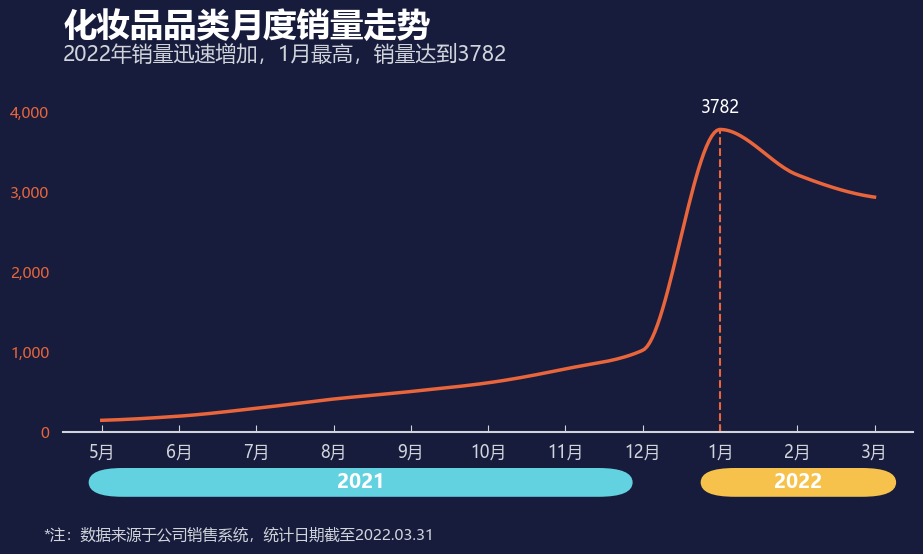

In [5]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import FancyBboxPatch
from scipy.interpolate import PchipInterpolator

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 1. 准备数据
months = ['5月', '6月', '7月', '8月', '9月', '10月', '11月', '12月', '1月', '2月', '3月']
sales = [146, 198, 296, 412, 506, 615, 789, 1021, 3782, 3215, 2936]
x = np.arange(len(months))

# 2. 颜色配置
bg_color = '#171B3C'        # 深藏青背景
text_white = '#FFFFFF'      # 白色文字
text_light = '#D1D5DB'      # 浅灰色文字/轴线
color_line = '#E9653B'      # 橙色折线
color_2021 = '#63D2E0'      # 2021 青色块
color_2022 = '#F6C24B'      # 2022 黄色块

# 3. 创建画布
fig, ax = plt.subplots(figsize=(10, 6))
fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)

# 4. 绘制平滑折线（使用 PchipInterpolator 防止平滑后过冲产生负数）
# Pchip 能保证曲线严格穿过原始数据点，且保持局部单调性
x_smooth = np.linspace(x.min(), x.max(), 300)
spl = PchipInterpolator(x, sales)
y_smooth = spl(x_smooth)

ax.plot(x_smooth, y_smooth, color=color_line, linewidth=2.5, zorder=3)

# 5. 添加最高点标注（1月份，索引为 8）
max_idx = 8
ax.vlines(x[max_idx], 0, sales[max_idx], colors=color_line, linestyles='--', linewidth=1.5, zorder=2)
ax.text(x[max_idx], sales[max_idx] + 150, str(sales[max_idx]), 
        color=text_white, ha='center', va='bottom', fontsize=12)

# 6. 配置坐标轴格式
# Y轴配置（橙色文字，千分位逗号，无刻度线）
ax.set_yticks([0, 1000, 2000, 3000, 4000])
ax.set_yticklabels(['0', '1,000', '2,000', '3,000', '4,000'], color=color_line, fontsize=11)
ax.set_ylim(0, 4500)
ax.tick_params(axis='y', length=0, pad=10)

# X轴配置（浅灰色文字，刻度线朝内）
ax.set_xticks(x)
ax.set_xticklabels(months, color=text_light, fontsize=12)
ax.set_xlim(-0.5, len(months) - 0.5)
ax.tick_params(axis='x', direction='in', length=5, colors=text_light, pad=8)

# 隐藏上、左、右边框，只保留底部轴线
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_color(text_light)
ax.spines['bottom'].set_linewidth(1.5)

# 7. 添加底部的 2021 和 2022 色块
# 使用 transform=ax.transAxes 将坐标系转换为相对画布的比例，方便定位
# 2021 色块
rect_2021 = FancyBboxPatch((0.03, -0.18), 0.64, 0.08, boxstyle="round,pad=0,rounding_size=0.04", 
                           transform=ax.transAxes, facecolor=color_2021, edgecolor='none', clip_on=False)
ax.add_patch(rect_2021)
ax.text(0.35, -0.14, '2021', transform=ax.transAxes, color=text_white, ha='center', va='center', fontsize=14, fontweight='bold')

# 2022 色块
rect_2022 = FancyBboxPatch((0.75, -0.18), 0.23, 0.08, boxstyle="round,pad=0,rounding_size=0.04", 
                           transform=ax.transAxes, facecolor=color_2022, edgecolor='none', clip_on=False)
ax.add_patch(rect_2022)
ax.text(0.865, -0.14, '2022', transform=ax.transAxes, color=text_white, ha='center', va='center', fontsize=14, fontweight='bold')

# 8. 添加标题、副标题和底部注释（严格左对齐）
ax.text(0.0, 1.10, '化妆品品类月度销量走势', transform=ax.transAxes, 
        color=text_white, fontsize=24, fontweight='bold', ha='left')
ax.text(0.0, 1.03, '2022年销量迅速增加，1月最高，销量达到3782', transform=ax.transAxes, 
        color=text_light, fontsize=15, ha='left')

fig.text(0.08, 0.04, '*注：数据来源于公司销售系统，统计日期截至2022.03.31', 
         color=text_light, fontsize=11, ha='left')

# 9. 调整布局，留出底部色块和顶部标题的空间
plt.subplots_adjust(top=0.82, bottom=0.22, left=0.1, right=0.95)
plt.show()

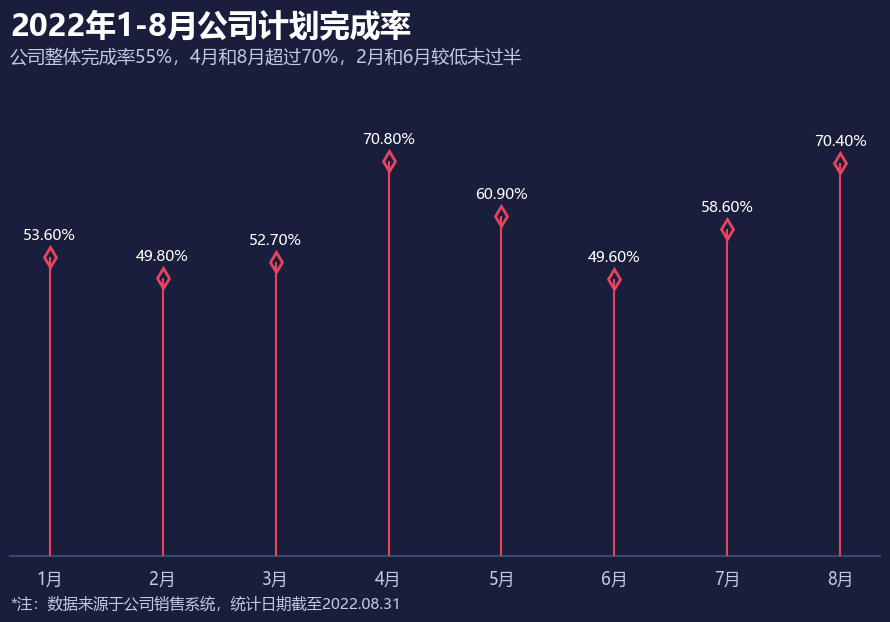

In [6]:
import matplotlib.pyplot as plt
import numpy as np

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 1. 准备数据
months = ['1月', '2月', '3月', '4月', '5月', '6月', '7月', '8月']
rates = [0.536, 0.498, 0.527, 0.708, 0.609, 0.496, 0.586, 0.704]
x = np.arange(len(months))

# 2. 颜色配置
bg_color = '#1A1E3D'        # 深藏青色背景
color_line = '#EA435F'      # 粉红色线条和菱形
text_white = '#FFFFFF'      # 主标题白色
text_light = '#C5C9DE'      # 副标题、标签浅灰
axis_color = '#40466B'      # 底部轴线深灰紫色

# 3. 创建画布
fig, ax = plt.subplots(figsize=(10, 6.5))
fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)

# 4. ✅ 绘制棒棒糖图
# 画垂直细线（从 y=0 开始，到对应的数值）
ax.vlines(x, 0, rates, color=color_line, linewidth=1.5, zorder=3)

# 画顶部的空心菱形（markerfacecolor='none' 表示内部透明）
ax.plot(x, rates, linestyle='none', marker='d', markersize=10,
        markerfacecolor='none', markeredgecolor=color_line, markeredgewidth=2, zorder=4)

# 5. 添加数据标签（在菱形上方）
for i, rate in enumerate(rates):
    ax.text(x[i], rate + 0.025, f'{rate:.2%}', ha='center', va='bottom', 
            color=text_white, fontsize=11, zorder=5)

# 6. 添加标题、副标题和底部注释（严格左对齐）
ax.text(0.0, 1.10, '2022年1-8月公司计划完成率', transform=ax.transAxes, 
        color=text_white, fontsize=22, fontweight='bold', ha='left')
ax.text(0.0, 1.04, '公司整体完成率55%，4月和8月超过70%，2月和6月较低未过半', transform=ax.transAxes, 
        color=text_light, fontsize=13, ha='left')

fig.text(0.08, 0.04, '*注：数据来源于公司销售系统，统计日期截至2022.08.31', 
         color=text_light, fontsize=11, ha='left')

# 7. 配置坐标轴格式
# Y轴：完全隐藏刻度和边框
ax.set_yticks([])
ax.spines['left'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# X轴：保留底部轴线，修改颜色，隐藏刻度线
ax.spines['bottom'].set_color(axis_color)
ax.spines['bottom'].set_linewidth(1.5)
ax.set_xticks(x)
ax.set_xticklabels(months, color=text_light, fontsize=12)
ax.tick_params(axis='x', length=0, pad=10)

# 设置Y轴范围，留出顶部标注的空间
ax.set_ylim(0, 0.85)

# 8. 调整布局并显示
plt.subplots_adjust(top=0.85, bottom=0.12, left=0.08, right=0.95)
plt.show()

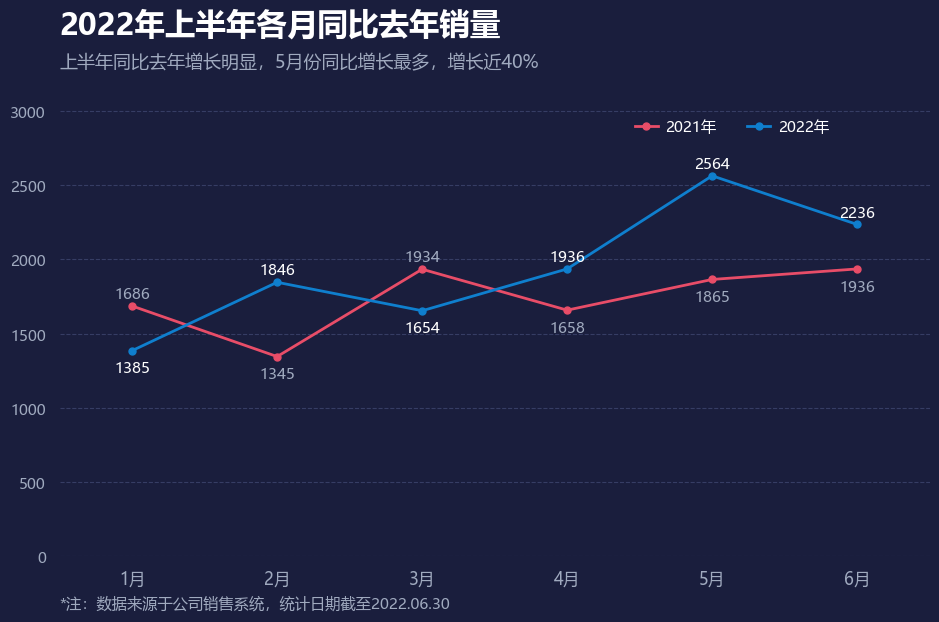

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.lines as mlines

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 1. 准备数据
months = ['1月', '2月', '3月', '4月', '5月', '6月']
sales_2021 = [1686, 1345, 1934, 1658, 1865, 1936]
sales_2022 = [1385, 1846, 1654, 1936, 2564, 2236]
x = np.arange(len(months))

# 2. 颜色配置
bg_color = '#1A1E3D'        # 深藏青背景
text_white = '#FFFFFF'      # 白色文字
text_light = '#A0AABF'      # 浅灰文字
grid_color = '#3E466E'      # 网格线颜色
color_2021 = '#E84D68'      # 2021粉红色
color_2022 = '#0F7FCE'      # 2022蓝色

# 3. 创建画布
fig, ax = plt.subplots(figsize=(10, 6.5))
fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)

# 4. 绘制折线图（带圆点标记）
ax.plot(x, sales_2021, color=color_2021, linewidth=2, marker='o', markersize=5, zorder=3)
ax.plot(x, sales_2022, color=color_2022, linewidth=2, marker='o', markersize=5, zorder=3)

# 5. ✅ 精准放置数据标签（根据原图的高低交错放置，避免重叠）
# 2021年数据标签位置
for i in range(len(x)):
    offset = 80 if i in [0, 2] else -120  # 1月和3月在上方，其余在下方
    ax.text(x[i], sales_2021[i] + offset, str(sales_2021[i]), 
            ha='center', va='center', color=text_light, fontsize=11, zorder=5)

# 2022年数据标签位置
for i in range(len(x)):
    offset = 80 if i in [1, 3, 4, 5] else -120  # 2,3,4,6月在上方，1月,3月在下方
    ax.text(x[i], sales_2022[i] + offset, str(sales_2022[i]), 
            ha='center', va='center', color=text_white, fontsize=11, zorder=5)

# 6. 自定义图例（右上角，无边框）
# 手动创建带圆点的线图例
legend_2021 = mlines.Line2D([], [], color=color_2021, marker='o', markersize=5, label='2021年', linewidth=2)
legend_2022 = mlines.Line2D([], [], color=color_2022, marker='o', markersize=5, label='2022年', linewidth=2)

# 将图例放在图表内部右上方，去掉边框
ax.legend(handles=[legend_2021, legend_2022], loc='upper right', bbox_to_anchor=(0.9, 0.95),
          frameon=False, labelcolor=text_white, fontsize=11, handlelength=1.5, handletextpad=0.5, ncol=2)

# 7. 添加标题、副标题和底部注释（严格左对齐）
ax.text(0.0, 1.10, '2022年上半年各月同比去年销量', transform=ax.transAxes, 
        color=text_white, fontsize=22, fontweight='bold', ha='left')
ax.text(0.0, 1.03, '上半年同比去年增长明显，5月份同比增长最多，增长近40%', transform=ax.transAxes, 
        color=text_light, fontsize=13, ha='left')

fig.text(0.08, 0.04, '*注：数据来源于公司销售系统，统计日期截至2022.06.30', 
         color=text_light, fontsize=11, ha='left')

# 8. 配置坐标轴与网格
# Y轴刻度
ax.set_yticks([0, 500, 1000, 1500, 2000, 2500, 3000])
ax.set_yticklabels(['0', '500', '1000', '1500', '2000', '2500', '3000'], color=text_light, fontsize=11)

# X轴刻度
ax.set_xticks(x)
ax.set_xticklabels(months, color=text_light, fontsize=12)

# 隐藏刻度线，设置范围
ax.tick_params(axis='x', length=0, pad=10)
ax.tick_params(axis='y', length=0, pad=10)
ax.set_ylim(0, 3200)
ax.set_xlim(-0.5, len(months) - 0.5)

# 隐藏四周的边框线
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

# 添加水平虚线网格（放在底层）
ax.yaxis.grid(True, linestyle='--', color=grid_color, alpha=0.8, zorder=1)
ax.set_axisbelow(True)

# 9. 调整布局并显示
plt.subplots_adjust(top=0.85, bottom=0.12, left=0.08, right=0.95)
plt.show()

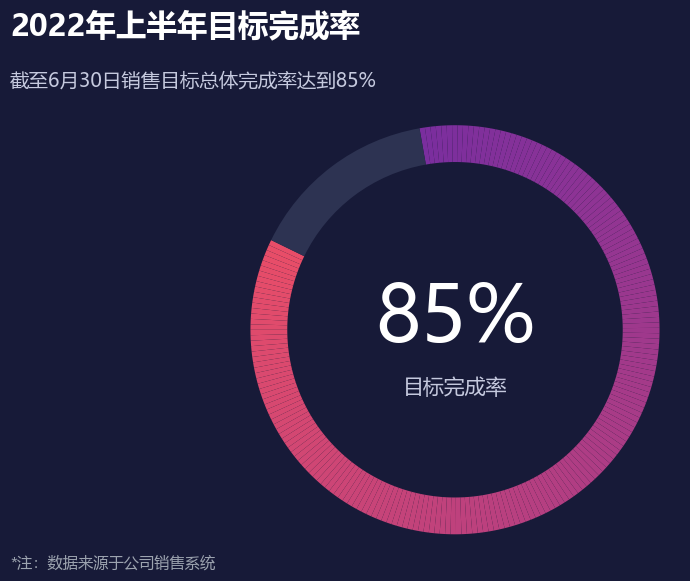

In [12]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Wedge
import matplotlib.colors as mcolors

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 1. 颜色配置
bg_color = '#171A38'        # 深藏青背景
color_unfinished = '#2D3352'# 未完成部分（深灰蓝）
color_text = '#FFFFFF'      # 主文字
color_subtext = '#C5C9DE'   # 浅灰文字

# 2. 创建画布
fig = plt.figure(figsize=(10, 6.5), facecolor=bg_color)

# 3. 配置圆环绘图区（✅ 增大画布空间，居中显示）
# [左边距, 底边距, 宽度, 高度]
ax = fig.add_axes([0.3, 0.05, 0.45, 0.75], facecolor=bg_color)
ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)
ax.set_aspect('equal')  # 保证绝对正圆
ax.axis('off')

# 4. ✅ 纯矢量绘制渐变圆环
cmap = mcolors.LinearSegmentedColormap.from_list('custom', ['#E84D68', '#7A2E9E'])
start_angle = 154
end_angle = 360 + 100
n_segments = 200

# 把圆环宽度从 0.15 加粗到 0.18
ring_width = 0.18 

for i in range(n_segments):
    a1 = start_angle + (end_angle - start_angle) * i / n_segments
    a2 = start_angle + (end_angle - start_angle) * (i + 1) / n_segments
    t = i / n_segments
    color = cmap(t)
    ax.add_patch(Wedge((0, 0), 1.0, a1, a2, width=ring_width, facecolor=color, edgecolor='none', zorder=2))

# 5. 绘制未完成的 15% 缺口
unfinished = Wedge((0, 0), 1.0, 100, 154, width=ring_width, facecolor=color_unfinished, edgecolor='none', zorder=3)
ax.add_patch(unfinished)

# 6. 添加中心文字（字体稍微放大，配合大圆环）
ax.text(0, 0.05, '85%', ha='center', va='center', color=color_text, fontsize=56)
ax.text(0, -0.28, '目标完成率', ha='center', va='center', color=color_subtext, fontsize=15)

# 7. 添加标题、副标题和底部注释
fig.text(0.08, 0.88, '2022年上半年目标完成率', color=color_text, fontsize=22, fontweight='bold')
fig.text(0.08, 0.80, '截至6月30日销售目标总体完成率达到85%', color=color_subtext, fontsize=14)

fig.text(0.08, 0.06, '*注：数据来源于公司销售系统', color='#9CA3AF', fontsize=11)

plt.show()

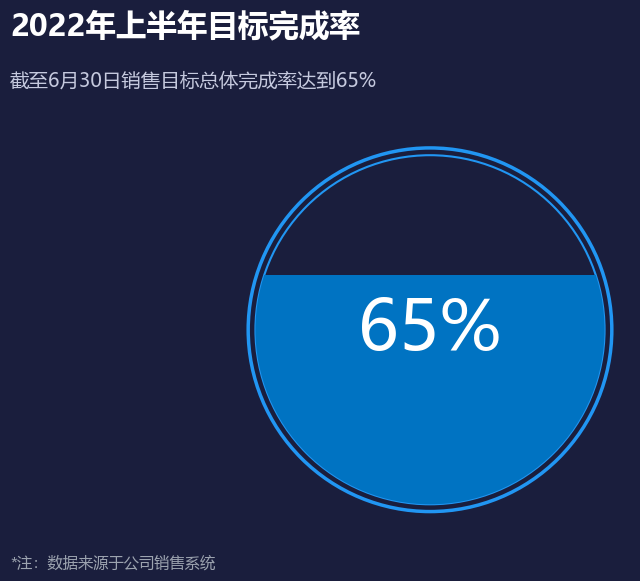

In [13]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Circle, Rectangle

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 1. 数据与颜色配置
percent = 0.65
bg_color = '#1A1E3D'        # 深藏青背景
water_color = '#0073C2'     # 水球蓝色
border_color = '#2196F3'    # 边框亮蓝色
text_white = '#FFFFFF'      # 白色文字
text_light = '#C5C9DE'      # 浅灰文字

# 2. 创建画布
fig = plt.figure(figsize=(10, 6.5), facecolor=bg_color)

# 3. 配置水球绘图区
ax = fig.add_axes([0.3, 0.1, 0.4, 0.65], facecolor=bg_color)
ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)
ax.set_aspect('equal')  # 保证正圆
ax.axis('off')

# 4. ✅ 绘制双层圆环边框
# 外层较粗的边框
outer_ring = Circle((0, 0), 1.0, facecolor='none', edgecolor=border_color, linewidth=2.5, zorder=2)
ax.add_patch(outer_ring)

# 内层稍细的边框
inner_ring = Circle((0, 0), 0.96, facecolor='none', edgecolor=border_color, linewidth=1.5, zorder=2)
ax.add_patch(inner_ring)

# 5. ✅ 绘制底部水平填充的水位
# 水面高度：0%在底部(-1)，100%在顶部(+1)，所以 65% 对应 -1 + 2*0.65 = 0.3
y_level = 2 * percent - 1

# 用矩形画水位，然后用圆形裁剪
water_rect = Rectangle((-1, -1), 2, y_level - (-1), facecolor=water_color, edgecolor='none', zorder=3)
ax.add_patch(water_rect)

# 裁剪成圆形
clip_circle = Circle((0, 0), 0.96, transform=ax.transData)
water_rect.set_clip_path(clip_circle)

# 6. 添加中心文字
ax.text(0, 0, '65%', ha='center', va='center', 
        color=text_white, fontsize=50, zorder=4)

# 7. 添加标题、副标题和底部注释（严格左对齐）
fig.text(0.08, 0.88, '2022年上半年目标完成率', color=text_white, fontsize=22, fontweight='bold')
fig.text(0.08, 0.80, '截至6月30日销售目标总体完成率达到65%', color=text_light, fontsize=14)
fig.text(0.08, 0.06, '*注：数据来源于公司销售系统', color='#9CA3AF', fontsize=11)

plt.show()

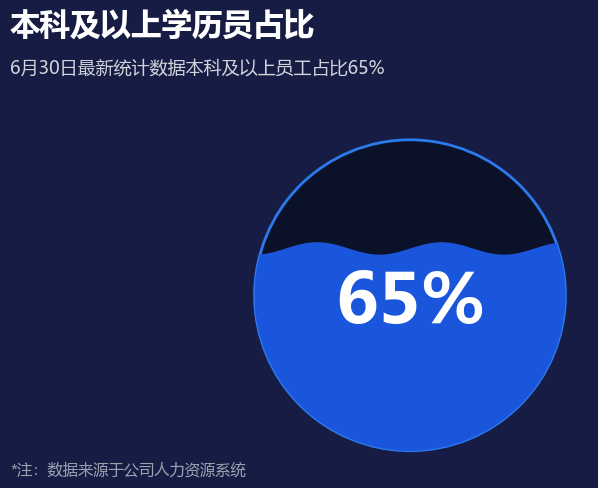

In [30]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 配色方案 (与之前深色仪表盘风格统一)
BG = '#171c45'        # 深蓝色背景 (贴合右图)
EMPTY = '#0a1128'     # 空球部分（更深的蓝色，形成对比）
WATER = '#1a56db'     # 水的颜色 (亮蓝色)
EDGE = '#2b7aee'      # 圆框边缘颜色

percent = 0.65

# 创建画布
fig = plt.figure(figsize=(10, 5.5), facecolor=BG)

# 1. 添加左对齐的主标题和副标题
fig.text(0.1, 0.85, '本科及以上学历员占比', color='#FFFFFF', fontsize=22, fontweight='bold', ha='left')
fig.text(0.1, 0.78, '6月30日最新统计数据本科及以上员工占比65%', color='#d1d5db', fontsize=13, ha='left')

# 2. 调整水球在画布中的位置 (留出顶部标题和底部备注的空间)
ax = fig.add_axes([0.3, 0.05, 0.4, 0.65], facecolor=BG)
ax.set_xlim(-1.15, 1.15)
ax.set_ylim(-1.15, 1.15)
ax.set_aspect('equal')
ax.axis('off')

# 3. 绘制球体边框 (亮蓝色细边框，深色内部)
ball = Circle((0, 0), 1.0, facecolor=EMPTY, edgecolor=EDGE, lw=2, zorder=1)
ax.add_patch(ball)

# 4. 水面正弦波计算
# 水位高度：0%在底部(-1)，100%在顶部(+1)
y_level = 2 * percent - 1
x = np.linspace(-1, 1, 1000)
# 调整波浪频率和振幅，使其接近右图（波峰波谷明显，平滑）
wave = y_level + 0.04 * np.sin(x * 2 * np.pi / 0.8)

# 5. 水体积填充与裁剪
clip = Circle((0, 0), 1.0, transform=ax.transData)
water = ax.fill_between(x, -1.0, wave, color=WATER, zorder=2)
water.set_clip_path(clip)

# 水面不需要描边，去掉原来的 plot 线条即可

# 6. 中心大号文字 (只保留65%)
ax.text(0, -0.05, '65%', ha='center', va='center',
        color='#FFFFFF', fontsize=50, fontweight='bold', zorder=4)

# 7. 底部数据来源备注
fig.text(0.1, 0.05, '*注：数据来源于公司人力资源系统', 
         color='#9CA3AF', fontsize=11, ha='left')

plt.show()

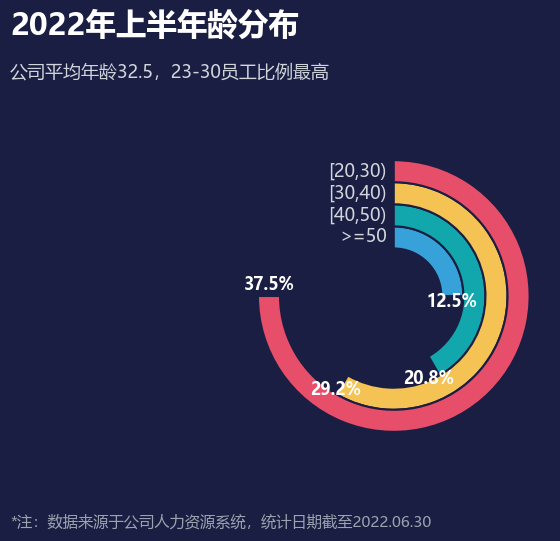

In [15]:
# -*- coding: utf-8 -*-
"""17 玉玦图 —— 完美复刻 Excel 仪表盘布局"""
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Wedge

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 配色方案与数据
BG = '#1A1E43'
ages   = ['>=50', '[40,50)', '[30,40)', '[20,30)']
shares = [0.125, 0.2083333, 0.2916667, 0.375]
colors = ['#37A2DA', '#11A7AD', '#F5C353', '#E74E69']   # 内圈 -> 外圈
percent_labels = ['12.5%', '20.8%', '29.2%', '37.5%']

fig = plt.figure(figsize=(9, 6), facecolor=BG)

# 主标题与副标题（左对齐）
fig.text(0.1, 0.88, '2022年上半年龄分布', color='#FFFFFF', fontsize=22, fontweight='bold', ha='left')
fig.text(0.1, 0.81, '公司平均年龄32.5，23-30员工比例最高', color='#d1d5db', fontsize=13, ha='left')

# 底部注释
fig.text(0.1, 0.06, '*注：数据来源于公司人力资源系统，统计日期截至2022.06.30', 
         color='#9CA3AF', fontsize=11, ha='left')

# 图表区域（适配宽画布，留出左侧空间给类别标签）
ax = fig.add_axes([0.3, 0.12, 0.4, 0.65], facecolor=BG)
# 调整X轴范围，给左侧的标签留出位置 (从 -1.5 到 1.15)
ax.set_xlim(-1.5, 1.15)
ax.set_ylim(-1.15, 1.15)
ax.set_aspect('equal')
ax.axis('off')

r_inner = 0.35     # 内孔径
r_outer = 1.0      # 外半径
n = len(ages)
thickness = (r_outer - r_inner) / n

# 绘制玉玦图
for i in range(n):
    ri = r_inner + i * thickness
    ro = ri + thickness
    # 计算角度：占比 / 0.5 * 360 (因为只画半圆/缺口圆)
    angle = shares[i] / 0.5 * 360
    
    # 1. 绘制圆环扇形（从12点钟方向顺时针绘制）
    ax.add_patch(Wedge((0, 0), ro, 90 - angle, 90, width=thickness,
                       facecolor=colors[i], edgecolor=BG, lw=1.5, zorder=2))

    # 计算该圆环的中线半径
    mid_r = (ri + ro) / 2
    
    # 2. 在圆环末端标注百分比 (末端角度为 90 - angle)
    th_end = np.radians(90 - angle)
    # 稍微向外偏移一点 (mid_r + 0.08)，避免文字压住圆环
    ax.text((mid_r + 0.00) * np.cos(th_end-0.08), (mid_r + 0.08) * np.sin(th_end-0.08), 
            percent_labels[i], ha='center', va='center', 
            color='#FFFFFF', fontsize=12, fontweight='bold', zorder=4)

    # 3. 在左侧缺口处标注数据范围 (垂直堆叠，与圆环中线对齐)
    # 放在 x = -0.05 位置，右对齐
    ax.text(-0.05, mid_r, ages[i], ha='right', va='center',
            color='#d1d5db', fontsize=13, zorder=4)

plt.show()

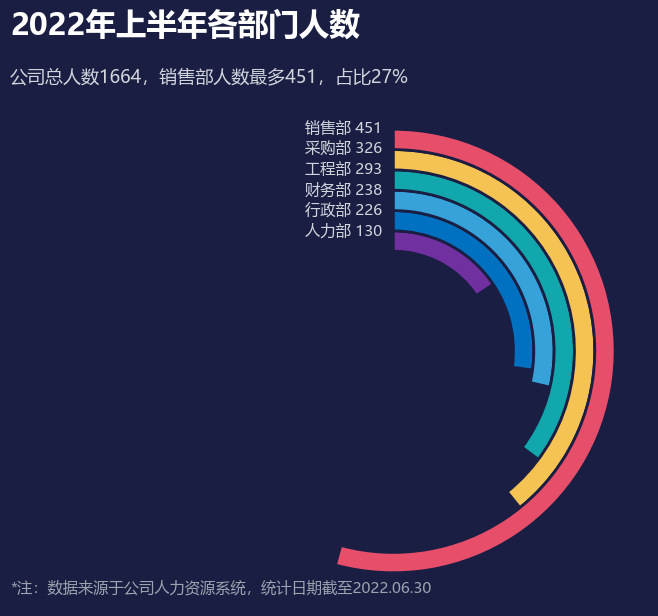

In [50]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Wedge

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False

BG = '#1A1E43'

depts  = ['人力部', '行政部', '财务部', '工程部', '采购部', '销售部']
people = [130, 226, 238, 293, 326, 451]
colors = ['#7030A0', '#0070C0', '#37A2DA', '#11A7AD', '#F5C353', '#E74E69']  # 内 → 外
total = 832   # 保持你的原逻辑

# 稍微加宽画布
fig = plt.figure(figsize=(10, 6.8), facecolor=BG)

# 左对齐标题和副标题
fig.text(0.1, 0.88, '2022年上半年各部门人数', color='#FFFFFF', fontsize=22, fontweight='bold', ha='left')
fig.text(0.1, 0.81, '公司总人数1664，销售部人数最多451，占比27%', color='#d1d5db', fontsize=13, ha='left')

# 底部注释
fig.text(0.1, 0.06, '*注：数据来源于公司人力资源系统，统计日期截至2022.06.30', 
         color='#9CA3AF', fontsize=11, ha='left')

# 调整坐标轴范围（左边界稍微调到 -1.0 即可，足够放字了）
ax = fig.add_axes([0.05, 0.04, 0.90, 0.75], facecolor=BG)
ax.set_xlim(-1.0, 1.15)   # 左边界从 -1.6 收紧到 -1.0
ax.set_ylim(-1.15, 1.15)
ax.set_aspect('equal')
ax.axis('off')

r_inner = 0.45     # 你的原参数
r_outer = 1.0      # 你的原参数
n = len(depts)
thickness = (r_outer - r_inner) / n

for i in range(n):
    ri = r_inner + i * thickness
    ro = ri + thickness
    angle = people[i] / total * 360
    ax.add_patch(Wedge((0, 0), ro, 90 - angle, 90, width=thickness,
                       facecolor=colors[i], edgecolor=BG, lw=2.0, zorder=2))
    
    # ✅ 核心修复：x 坐标改为 -0.05，右对齐，这样文字就贴着圆环起点（12点钟方向）了
    ax.text(-0.05, ro, f'{depts[i]} {people[i]}', ha='right', va='center',
            color='#d1d5db', fontsize=, zorder=4)

plt.show()

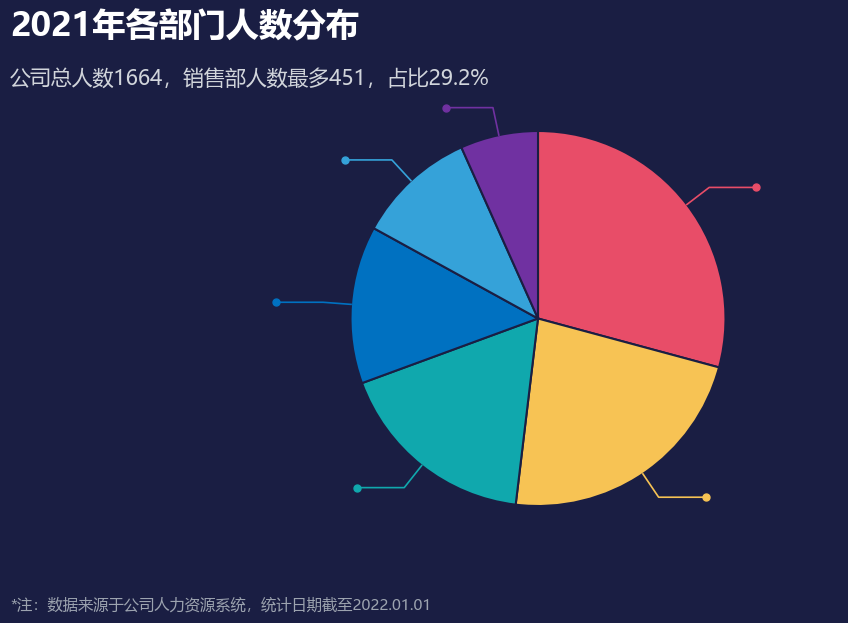

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 1. 准备数据
sizes = [29.2, 22.7, 17.5, 13.6, 10.3, 6.7]
# 从12点钟方向顺时针的颜色 (精准提取原图颜色)
colors = ['#E84D68', '#F7C354', '#10A8AD', '#0071C1', '#35A2D9', '#7031A1']

# 2. 创建画布与背景色（标准宽幅比例，深藏青色背景）
fig = plt.figure(figsize=(12, 7), facecolor='#1A1E43')

# ✅ 调整图表位置，使饼图居中（给左侧标题和四周引出线留出空间）
ax = fig.add_axes([0.2, 0.1, 0.6, 0.75], facecolor='#1A1E43')

# 3. 绘制饼图
wedges, texts = ax.pie(
    sizes, 
    colors=colors, 
    startangle=90,          # 从12点钟方向开始
    counterclock=False,     # 顺时针排列
    wedgeprops={'edgecolor': '#1A1E43', 'linewidth': 1.5} # 扇区间隙使用背景色
)

# 4. ✅ 精准复刻 Excel 标准引出线 (斜线向外 + 水平线 + 末端小圆点)
for i, wedge in enumerate(wedges):
    # 获取当前扇形的中间角度
    theta1, theta2 = wedge.theta1, wedge.theta2
    mid_angle = np.radians((theta1 + theta2) / 2)
    
    # 起点：饼图边缘 (半径1.0)
    x1 = np.cos(mid_angle)
    y1 = np.sin(mid_angle)
    
    # 拐点：向外延伸一段距离 (半径1.15)
    r_bend = 1.15
    x2 = r_bend * np.cos(mid_angle)
    y2 = r_bend * np.sin(mid_angle)
    
    # 终点：水平延伸 (向左或向右延伸0.25)
    x3 = x2 + 0.25 if x2 > 0 else x2 - 0.25
    y3 = y2
    
    # 绘制折线 (斜线 + 水平线)
    ax.plot([x1, x2, x3], [y1, y2, y3], color=colors[i], linewidth=1.2, zorder=5)
    
    # 在水平线末端绘制小圆点
    ax.plot(x3, y3, marker='o', markersize=5, color=colors[i], zorder=10)

# 5. 添加标题、副标题和底部注释（严格左对齐）
fig.text(0.06, 0.88, '2021年各部门人数分布', color='#FFFFFF', fontsize=24, fontweight='bold', ha='left')
fig.text(0.06, 0.81, '公司总人数1664，销售部人数最多451，占比29.2%', color='#D1D5DB', fontsize=15, ha='left')
fig.text(0.06, 0.06, '*注：数据来源于公司人力资源系统，统计日期截至2022.01.01', 
         color='#9CA3AF', fontsize=11, ha='left')

# 6. 最终调整，隐藏坐标轴
ax.set_xlim(-1.6, 1.6)
ax.set_ylim(-1.4, 1.4)
ax.axis('off') 

plt.show()

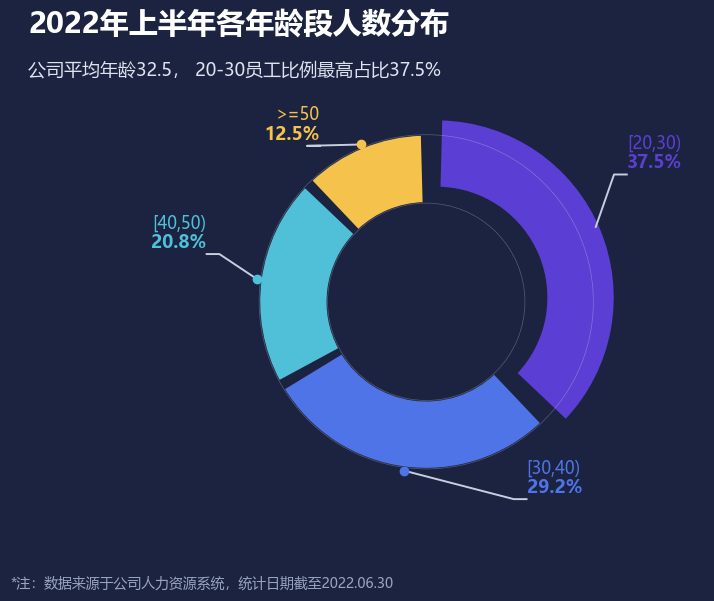

In [28]:
# -*- coding: utf-8 -*-
"""复现：2022年上半年各年龄段人数分布 —— 环形图（Jupyter 内联显示版）"""
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import Wedge

mpl.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Noto Sans CJK JP"]
mpl.rcParams["axes.unicode_minus"] = False

BG = "#1b2340"

labels = ["[20,30)", "[30,40)", "[40,50)", ">=50"]
pcts   = [37.5, 29.2, 20.8, 12.5]
colors = ["#5b3fd4", "#4f74e8", "#4fc0d8", "#f5c24b"]

fig, ax = plt.subplots(figsize=(9, 6.2), facecolor=BG)
ax.set_facecolor(BG)
ax.set_xlim(-1.75, 1.75)
ax.set_ylim(-1.5, 1.5)
ax.set_aspect("equal")
ax.axis("off")

R0, R1 = 0.62, 1.05
GAP = 1.5
start = 90
explode_idx = 0
exploded = 0.07

mid_angles = []
for i, (lab, p, c) in enumerate(zip(labels, pcts, colors)):
    span = p / 100 * 360
    th0, th1 = start - GAP, start - span + GAP
    off = exploded if i == explode_idx else 0.0
    mid = start - span / 2
    dx, dy = off * np.cos(np.deg2rad(mid)), off * np.sin(np.deg2rad(mid))
    ax.add_patch(Wedge((dx, dy), R1 + off, th1, th0, width=R1 - R0,
                       facecolor=c, edgecolor=BG, lw=1.5, zorder=3))
    mid_angles.append(mid)
    start -= span

# 环内细微同心弧纹理
for r in np.linspace(R0 + 0.07, R1 - 0.06, 5):
    ax.add_patch(Wedge((0, 0), R1, 0, 360, width=R1 - R0, facecolor="none",
                       edgecolor="#ffffff", lw=0.6, alpha=0.05, zorder=4))

# ---------- 引导线 + 标签 ----------
def pol(ang_deg, r):
    a = np.deg2rad(ang_deg)
    return (r * np.cos(a), r * np.sin(a))

def annotate_slice(i, dot_r, kink, tx, side):
    """灰色折线 + 彩色圆点 + 两行彩色文字；side='left'/'right'"""
    off = exploded if i == explode_idx else 0.0
    dot = pol(mid_angles[i], dot_r + off)
    ax.plot([dot[0], kink[0], tx], [dot[1], kink[1], kink[1]],
            color="#c8cde0", lw=1.4, zorder=5)
    ax.plot(*dot, marker="o", ms=6, color=colors[i], zorder=6)
    ha = "left" if side == "right" else "right"
    ax.text(tx, kink[1] + 0.14, labels[i], color=colors[i], fontsize=12,
            ha=ha, va="bottom", zorder=6)
    ax.text(tx, kink[1] + 0.02, f"{pcts[i]}%", color=colors[i], fontsize=13,
            fontweight="bold", ha=ha, va="bottom", zorder=6)

annotate_slice(0, R1 + 0.02, (1.18, 0.80), 1.26, "right")    # [20,30) 右上
annotate_slice(1, R1 + 0.02, (0.55, -1.24), 0.63, "right")   # [30,40) 右下
annotate_slice(2, R1 + 0.02, (-1.30, 0.30), -1.38, "left")   # [40,50) 左
annotate_slice(3, R1 + 0.02, (-0.75, 0.98), -0.67, "left")   # >=50 左上

# ---------- 标题 / 副标题 / 脚注 ----------
fig.text(0.07, 0.93, "2022年上半年各年龄段人数分布", color="white", fontsize=21, fontweight="bold")
fig.text(0.07, 0.862, "公司平均年龄32.5， 20-30员工比例最高占比37.5%",
         color="#dfe3f0", fontsize=13)
fig.text(0.05, 0.035, "*注：数据来源于公司人力资源系统，统计日期截至2022.06.30",
         color="#9aa3bf", fontsize=10)

plt.show()


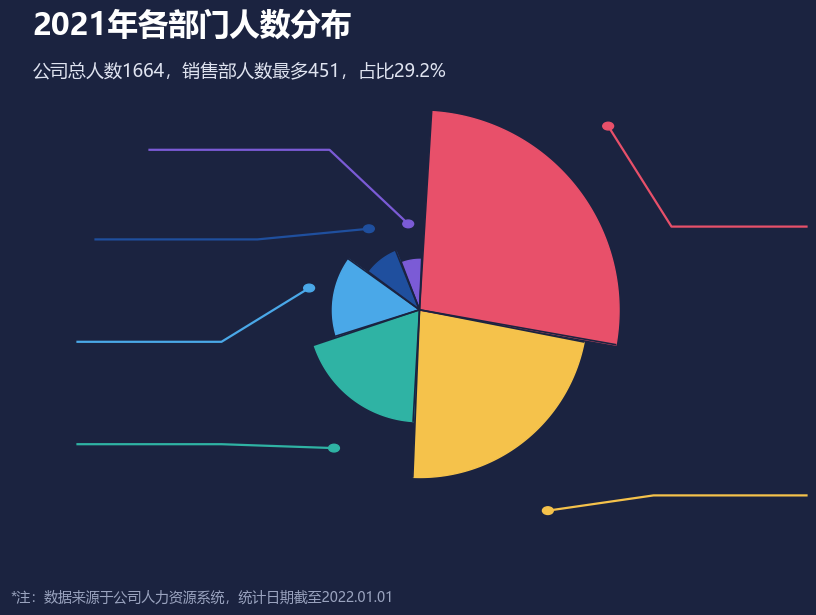

In [24]:
# -*- coding: utf-8 -*-
"""复现：2021年各部门人数分布 —— 爆炸式玫瑰图（Jupyter 内联显示版）"""
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

# Windows 常用中文字体（按顺序尝试，找不到会自动跳到下一个）
mpl.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Noto Sans CJK JP", "Arial Unicode MS"]
mpl.rcParams["axes.unicode_minus"] = False

BG = "#1b2340"                               # 深蓝背景
labels = ["销售部", "技术部", "运营部", "产品部", "人事部", "财务部"]
values = [451, 380, 320, 250, 150, 113]      # 合计 1664
colors = ["#e8506a", "#f5c24b", "#2fb3a4", "#4aa8e8", "#1f4f9e", "#7b5bd6"]

total = sum(values)
N = len(values)

fig = plt.figure(figsize=(9, 6.4), facecolor=BG)
ax = fig.add_subplot(111, polar=True)
ax.set_facecolor(BG)
ax.set_position([0.27, 0.09, 0.46, 0.80])

ax.set_xticks([]); ax.set_yticks([])
ax.spines["polar"].set_visible(False)
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)          # 顺时针
ax.set_ylim(0, 1.3)

gap = np.deg2rad(1.0)               # 扇形间缝隙
theta_acc = np.deg2rad(3)           # 从 12 点钟略偏右开始
start_angles, spans = [], []
for v in values:
    span = v / total * 2 * np.pi
    start_angles.append(theta_acc)
    spans.append(span)
    theta_acc += span

# 半径缩放：半径也随人数变化，突出销售部/技术部
scale_r = {0: 1.25, 1: 1.05, 2: 0.70, 3: 0.55, 4: 0.40, 5: 0.32}

for i in range(N):
    th0 = start_angles[i] + gap / 2
    th1 = start_angles[i] + spans[i] - gap / 2
    theta = np.linspace(th0, th1, 100)
    ax.fill_between(theta, 0, scale_r[i], color=colors[i], zorder=3 + N - i)
    ax.plot([th0, th0], [0, scale_r[i]], color=BG, lw=1.2, zorder=10)
    ax.plot([th1, th1], [0, scale_r[i]], color=BG, lw=1.2, zorder=10)

# ---------- 引导线 ----------
cx, cy = 0.50, 0.49                 # 极坐标圆心在 figure 中的位置
def edge_pt(i, r):
    """扇形中线、半径 r 处的 figure 坐标"""
    a = start_angles[i] + spans[i] / 2      # 弧度
    return (cx + r * 0.23 * np.sin(a), cy + r * 0.40 * np.cos(a))

def leader(i, r_dot, corner_x, end):
    p_out = edge_pt(i, r_dot)
    corner = (corner_x, end[1])
    xs, ys = zip(p_out, corner, end)
    fig.lines.append(mpl.lines.Line2D(xs, ys, transform=fig.transFigure,
                                      color=colors[i], lw=1.6, zorder=20, clip_on=False))
    fig.patches.append(mpl.patches.Circle(p_out, 0.006, transform=fig.transFigure,
                                          color=colors[i], zorder=21, clip_on=False))

leader(0, 1.16, 0.78, (0.93, 0.62))   # 销售部 → 右
leader(1, 1.00, 0.76, (0.93, 0.20))   # 技术部 → 右下
leader(2, 0.68, 0.28, (0.12, 0.28))   # 运营部 → 左
leader(3, 0.54, 0.28, (0.12, 0.44))   # 产品部 → 左
leader(4, 0.40, 0.32, (0.14, 0.60))   # 人事部 → 左上
leader(5, 0.34, 0.40, (0.20, 0.74))   # 财务部 → 左上

# ---------- 标题 / 副标题 / 脚注 ----------
fig.text(0.07, 0.92, "2021年各部门人数分布", color="white", fontsize=22, fontweight="bold")
fig.text(0.07, 0.855, "公司总人数1664，销售部人数最多451，占比29.2%",
         color="#dfe3f0", fontsize=13)
fig.text(0.045, 0.035, "*注：数据来源于公司人力资源系统，统计日期截至2022.01.01",
         color="#9aa3bf", fontsize=10)

plt.show()          # Jupyter 中直接内联显示


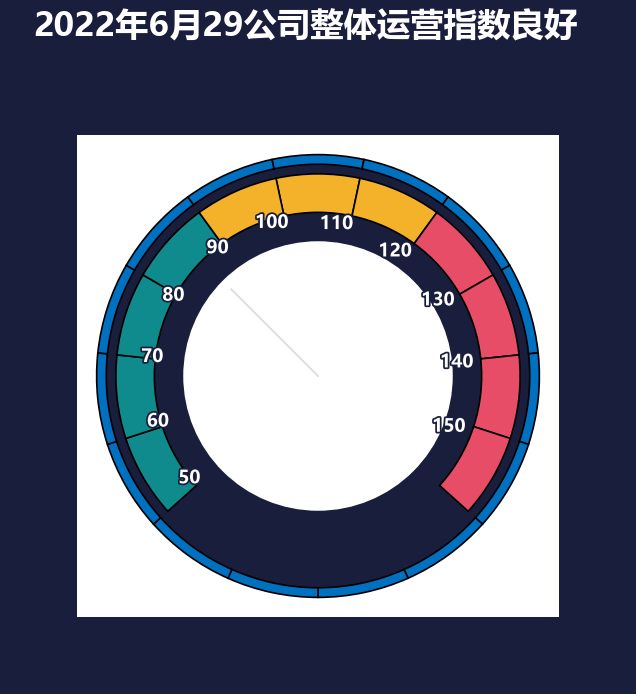

In [22]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Wedge, Rectangle, Circle
import matplotlib.patheffects as path_effects

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 1. 创建画布
fig, ax = plt.subplots(figsize=(10, 8))
fig.patch.set_facecolor('#1A1E3D')
ax.set_facecolor('#1A1E3D')

ax.set_xlim(-1.6, 1.6)
ax.set_ylim(-1.6, 1.6)
ax.set_aspect('equal')
ax.axis('off')

# 2. 白色正方形底板
rect = Rectangle((-1.25, -1.25), 2.5, 2.5, facecolor='white', edgecolor='none', zorder=1)
ax.add_patch(rect)

# 3. 深蓝色大底板
inner_bg = Circle((0, 0), 1.15, facecolor='#1A1E3D', edgecolor='none', zorder=2)
ax.add_patch(inner_bg)

# 4. 循环绘制环形刻度盘
for i in range(15):
    center_angle = 90 - i * 24
    theta1 = center_angle + 12  # 逆时针边界线（左侧）
    theta2 = center_angle - 12  # 顺时针边界线（右侧）
    
    # 【外圈蓝色环】
    ax.add_patch(Wedge((0, 0), 1.15, theta2, theta1, width=0.05, 
                       facecolor='#0070C0', edgecolor='black', lw=1.2, zorder=3))
    
    # 中间彩色块和数字
    if i <= 5 or i >= 10:
        if i <= 5:
            val = 100 + i * 10
        else:
            val = 50 + (i - 10) * 10
            
        if 50 <= val <= 80:
            c = '#0F8B8D' # 青色
        elif 90 <= val <= 110:
            c = '#F3B229' # 黄色
        elif 120 <= val <= 150:
            c = '#E84D68' # 红色
            
        # 【中间彩色刻度环】
        ax.add_patch(Wedge((0, 0), 1.05, theta2, theta1, width=0.20, 
                           facecolor=c, edgecolor='black', lw=1.2, zorder=4))
        
        # ✅ 核心修改：调整位置，紧靠刻度线
        # 角度靠近左边的分割线 (theta1 - 1度)
        text_angle = theta1 - 1 
        # 半径提高到 0.81，紧贴彩色块的下边缘
        r_text = 0.81 
        
        rad = np.radians(text_angle)
        x_text = r_text * np.cos(rad)
        y_text = r_text * np.sin(rad)
        
        # 使用 ha='right'，让文字右侧顶住刻度线
        text = ax.text(x_text, y_text, str(val), ha='right', va='center', 
                       color='#FFFFFF', fontsize=13, fontweight='bold', zorder=6)
        # 加一点深色描边
        text.set_path_effects([path_effects.withStroke(linewidth=2.5, foreground='#1A1E3D')])

# 5. 中心白色圆盘
center_circle = Circle((0, 0), 0.70, facecolor='white', edgecolor='none', zorder=5)
ax.add_patch(center_circle)

# 6. 半透明指针
ax.plot([0, -0.45], [0, 0.45], color='#D3D3D3', linewidth=1.5, alpha=0.7, zorder=7)

# 7. 标题
fig.text(0.5, 0.92, '2022年6月29公司整体运营指数良好', color='white', fontsize=24, fontweight='bold', ha='center')

plt.show()

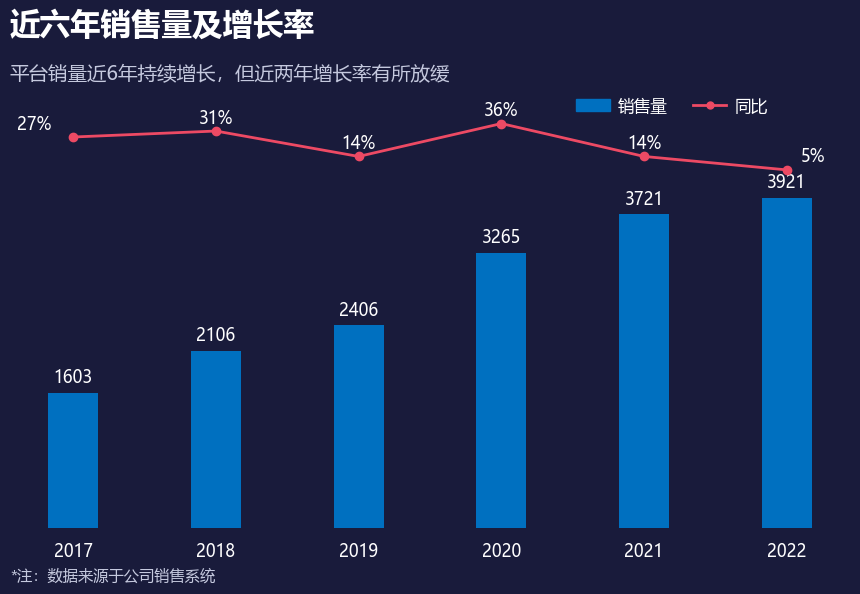

In [29]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.patches as mpatches
import matplotlib.lines as mlines

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 1. 准备数据
years = ['2017', '2018', '2019', '2020', '2021', '2022']
sales = [1603, 2106, 2406, 3265, 3721, 3921]
growth = [27, 31, 14, 36, 14, 5]
x = np.arange(len(years))

# 2. ✅ 重新校准坐标映射：抬高基线，拉开折线
min_pct, max_pct = 5, 36
# 把基线从 4050 拔高到 4250，起伏比例调整为 550
base_y, height_scale = 4250, 550 
y_vis = [base_y + (g - min_pct) / (max_pct - min_pct) * height_scale for g in growth]

# 3. 颜色配置
bg_color = '#191B3B'        # 深藏青背景
text_white = '#FFFFFF'      # 白色文字
text_light = '#C5C9DE'      # 浅灰文字
color_bar = '#0070C0'       # 柱状图蓝色
color_line = '#ED4A64'      # 折线图红色

# 4. 创建画布
fig, ax = plt.subplots(figsize=(10, 6.5))
fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)

# 5. 绘制柱状图
width = 0.35
bars = ax.bar(x, sales, width=width, color=color_bar, zorder=3)

# 添加柱状图数据标签
for bar, val in zip(bars, sales):
    ax.text(bar.get_x() + bar.get_width()/2, val + 80, str(val),
             ha='center', va='bottom', color=text_white, fontsize=12, zorder=4)

# 6. ✅ 绘制折线图
ax.plot(x, y_vis, color=color_line, linewidth=2, marker='o', markersize=6, zorder=5)

# 添加折线图数据标签
for i, val in enumerate(growth):
    if i == 0:
        # 2017年稍微往左偏
        ax.text(x[i] - 0.15, y_vis[i] + 50, f'{val}%',
                ha='right', va='bottom', color=text_white, fontsize=12, zorder=6)
    elif i == 5:
        # ✅ 2022年（5%）：文字向右上偏移，彻底避开 3921
        ax.text(x[i] + 0.1, y_vis[i] + 60, f'{val}%',
                ha='left', va='bottom', color=text_white, fontsize=12, zorder=6)
    else:
        ax.text(x[i], y_vis[i] + 50, f'{val}%',
                ha='center', va='bottom', color=text_white, fontsize=12, zorder=6)

# 7. 配置坐标轴
ax.set_xticks(x)
ax.set_xticklabels(years, color=text_white, fontsize=12)
ax.tick_params(axis='x', length=0, pad=10)

# 隐藏 Y 轴刻度和所有边框
ax.set_yticks([])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

# 设置 Y 轴范围
ax.set_ylim(0, 5400)

# 8. 自定义图例
legend_bar = mpatches.Patch(color=color_bar, label='销售量')
legend_line = mlines.Line2D([], [], color=color_line, marker='o', markersize=5, label='同比', linewidth=2)

ax.legend(handles=[legend_bar, legend_line], loc='upper right', bbox_to_anchor=(0.92, 0.98),
           frameon=False, labelcolor=text_white, fontsize=12, 
           ncol=2, handletextpad=0.5, columnspacing=1.5)

# 9. 添加标题、副标题和底部注释
fig.text(0.08, 0.88, '近六年销售量及增长率', color=text_white, fontsize=22, fontweight='bold')
fig.text(0.08, 0.81, '平台销量近6年持续增长，但近两年增长率有所放缓', color=text_light, fontsize=14)
fig.text(0.08, 0.04, '*注：数据来源于公司销售系统', color=text_light, fontsize=11)

# 10. 调整布局
plt.subplots_adjust(top=0.82, bottom=0.12, left=0.08, right=0.92)
plt.show()

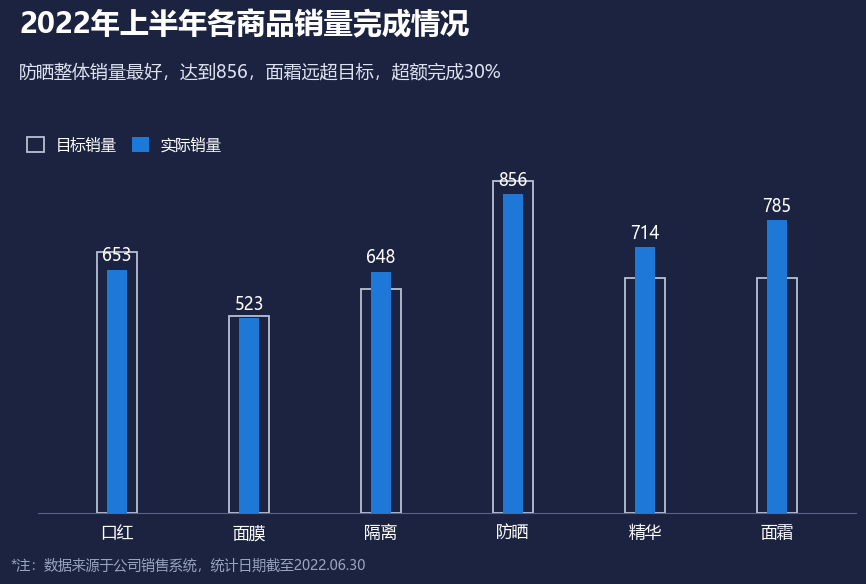

In [38]:
# -*- coding: utf-8 -*-
"""复现：2022年上半年各商品销量完成情况 —— 空心目标柱 + 实际柱（Jupyter 内联显示版）"""
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import Patch

mpl.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Noto Sans CJK JP"]
mpl.rcParams["axes.unicode_minus"] = False

BG    = "#1b2340"
C_ACT = "#1e78d8"      # 实际销量蓝
C_OUT = "#b9c0d4"      # 目标空心柱描边

products = ["口红", "面膜", "隔离", "防晒", "精华", "面霜"]
target   = [700, 530, 600, 890, 630, 630]   # 目标（按原图空心柱高度估算）
actual   = [653, 523, 648, 856, 714, 785]   # 实际（原图标注）

fig, ax = plt.subplots(figsize=(9.2, 6.0), facecolor=BG)
ax.set_facecolor(BG)
fig.subplots_adjust(left=0.08, right=0.97, top=0.72, bottom=0.13)

x = np.arange(len(products))
W = 0.15

# 目标：灰色描边空心柱（更宽，在后面）
ax.bar(x, target, width=0.30, facecolor="none", edgecolor=C_OUT,
       lw=1.3, zorder=3, label="目标销量")
# 实际：蓝色实心柱（更窄，在前）
bars = ax.bar(x, actual, width=W, color=C_ACT, zorder=4, label="实际销量")

# 实际销量数值标签
for xi, v in zip(x, actual):
    ax.text(xi, v + 22, str(v), color="white", fontsize=12,
            ha="center", zorder=6)

# ---------- 坐标轴样式 ----------
ax.set_xlim(-0.6, len(products) - 0.4)
ax.set_ylim(0, 950)
ax.set_xticks(x)
ax.set_xticklabels(products, color="white", fontsize=12)
ax.set_yticks([])                       # 原图无 y 轴刻度
ax.tick_params(axis="x", length=0, pad=8)

ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
ax.spines["bottom"].set_visible(True)
ax.spines["bottom"].set_color("#5a6488")

# ---------- 图例（空心方块 + 实心方块） ----------
handles = [
    Patch(fc="none", ec=C_OUT, lw=1.3, label="目标销量"),
    Patch(fc=C_ACT, label="实际销量"),
]
ax.legend(handles=handles, ncol=2, loc="upper left", bbox_to_anchor=(-0.03, 1.10),
          frameon=False, fontsize=11, handlelength=1.1, handleheight=1.1,
          columnspacing=1.0, labelcolor="white")

# ---------- 标题 / 副标题 / 脚注 ----------
fig.text(0.06, 0.93, "2022年上半年各商品销量完成情况", color="white",
         fontsize=21, fontweight="bold")
fig.text(0.06, 0.855, "防晒整体销量最好，达到856，面霜远超目标，超额完成30%",
         color="#dfe3f0", fontsize=13)
fig.text(0.05, 0.035, "*注：数据来源于公司销售系统，统计日期截至2022.06.30",
         color="#9aa3bf", fontsize=10)

plt.show()


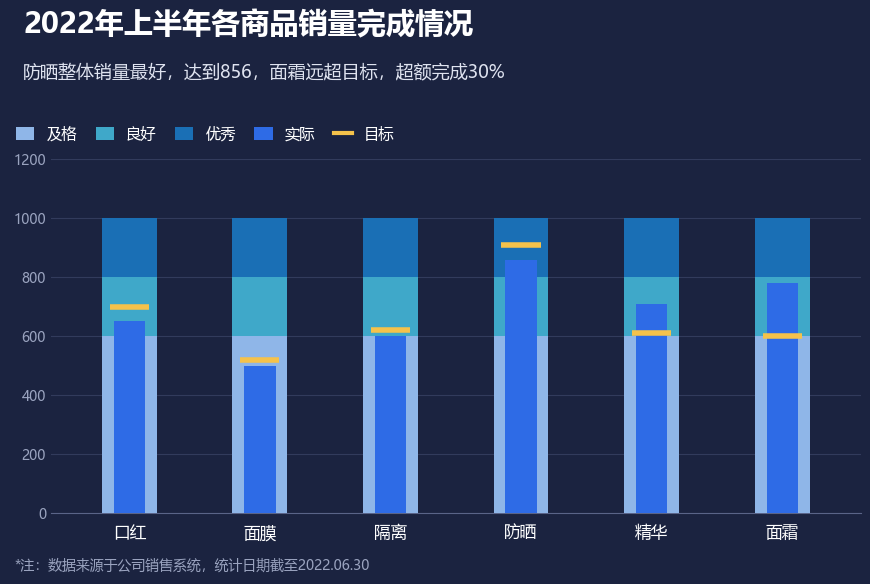

In [34]:
# -*- coding: utf-8 -*-
"""复现：2022年上半年各商品销量完成情况 —— 子弹图（Jupyter 内联显示版）"""
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import Patch, Rectangle
from matplotlib.lines import Line2D

mpl.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Noto Sans CJK JP"]
mpl.rcParams["axes.unicode_minus"] = False

BG      = "#1b2340"
C_PASS  = "#8fb6e8"   # 及格
C_GOOD  = "#3fa8c9"   # 良好
C_EXC   = "#1a6fb5"   # 优秀
C_ACT   = "#2e6be6"   # 实际
C_TGT   = "#f5c24b"   # 目标

products = ["口红", "面膜", "隔离", "防晒", "精华", "面霜"]
actual   = [650, 500, 600, 856, 710, 780]
target   = [700, 520, 620, 910, 610, 600]
pass_v, good_v, exc_v = 600, 800, 1000     # 及格/良好/优秀 分档

fig, ax = plt.subplots(figsize=(9.2, 6.0), facecolor=BG)
ax.set_facecolor(BG)
fig.subplots_adjust(left=0.09, right=0.97, top=0.72, bottom=0.13)

x = np.arange(len(products))
W_BG, W_ACT, W_TGT = 0.42, 0.24, 0.30      # 背景条/实际条/目标刻度宽度

for i in range(len(products)):
    # 背景分档堆叠条（及格 → 良好 → 优秀）
    ax.bar(x[i], pass_v, width=W_BG, color=C_PASS, zorder=3)
    ax.bar(x[i], good_v - pass_v, bottom=pass_v, width=W_BG, color=C_GOOD, zorder=3)
    ax.bar(x[i], exc_v - good_v, bottom=good_v, width=W_BG, color=C_EXC, zorder=3)
    # 实际销量（细条叠加）
    ax.bar(x[i], actual[i], width=W_ACT, color=C_ACT, zorder=4)
    # 目标（黄色短横线）
    ax.plot([x[i] - W_TGT / 2, x[i] + W_TGT / 2], [target[i], target[i]],
            color=C_TGT, lw=4, zorder=5, solid_capstyle="butt")

# ---------- 坐标轴样式 ----------
ax.set_xlim(-0.6, len(products) - 0.4)
ax.set_ylim(0, 1200)
ax.set_yticks(range(0, 1201, 200))
ax.set_xticks(x)
ax.set_xticklabels(products, color="white", fontsize=12)
ax.tick_params(axis="y", colors="#9aa3bf", labelsize=10, length=0)
ax.tick_params(axis="x", length=0, pad=8)

ax.grid(axis="y", color="#323b5c", lw=0.8, zorder=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.spines["bottom"].set_visible(True)
ax.spines["bottom"].set_color("#5a6488")

# ---------- 图例 ----------
handles = [
    Patch(fc=C_PASS, label="及格"), Patch(fc=C_GOOD, label="良好"),
    Patch(fc=C_EXC, label="优秀"), Patch(fc=C_ACT, label="实际"),
    Line2D([0], [0], color=C_TGT, lw=3, label="目标"),
]
leg = ax.legend(handles=handles, ncol=5, loc="upper left",
                bbox_to_anchor=(-0.06, 1.13), frameon=False,
                fontsize=11, handlelength=1.2, handleheight=1.0,
                columnspacing=1.2, labelcolor="white")

# ---------- 标题 / 副标题 / 脚注 ----------
fig.text(0.06, 0.93, "2022年上半年各商品销量完成情况", color="white",
         fontsize=21, fontweight="bold")
fig.text(0.06, 0.855, "防晒整体销量最好，达到856，面霜远超目标，超额完成30%",
         color="#dfe3f0", fontsize=13)
fig.text(0.05, 0.035, "*注：数据来源于公司销售系统，统计日期截至2022.06.30",
         color="#9aa3bf", fontsize=10)

plt.show()


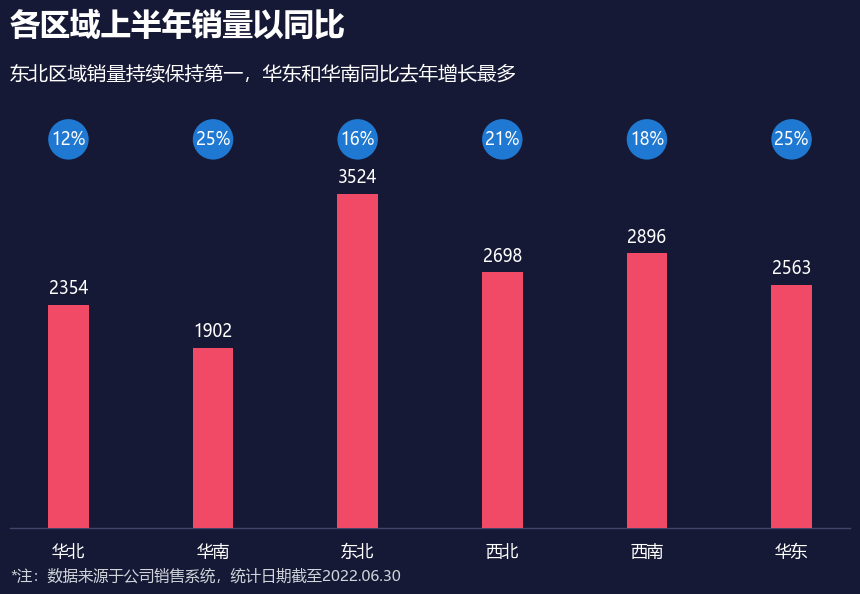

In [36]:
import matplotlib.pyplot as plt
import numpy as np

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 1. 准备数据
regions = ['华北', '华南', '东北', '西北', '西南', '华东']
sales = [2354, 1902, 3524, 2698, 2896, 2563]
yoy = ['12%', '25%', '16%', '21%', '18%', '25%']
x = np.arange(len(regions))

# 2. 颜色配置
bg_color = '#161935'        # 深藏青背景
text_white = '#FFFFFF'      # 白色文字
text_light = '#D1D5DB'      # 浅灰文字
color_bar = '#F04A66'       # 粉红色柱体
color_bubble = '#1F78D1'    # 蓝色气泡
color_axis = '#40466B'      # 底部轴线颜色

# 3. 创建画布
fig, ax = plt.subplots(figsize=(10, 6.5))
fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)

# 4. 绘制柱状图
width = 0.28
bars = ax.bar(x, sales, width=width, color=color_bar, zorder=3)

# 5. 添加柱子顶部的销量标签
for bar, val in zip(bars, sales):
    ax.text(bar.get_x() + bar.get_width()/2, val + 80, str(val), 
            ha='center', va='bottom', color=text_white, fontsize=12, zorder=4)

# 6. ✅ 绘制悬浮的蓝色圆形气泡与同比标签
bubble_y = 4100  # 气泡所在的统一高度（Y轴坐标）
for i, val in enumerate(yoy):
    # 画蓝色圆（使用 scatter 函数，s 控制面积大小，使其呈现完美的圆形）
    ax.scatter(x[i], bubble_y, s=850, color=color_bubble, zorder=4, edgecolors='none')
    # 在圆心写上白色百分比
    ax.text(x[i], bubble_y, val, ha='center', va='center', color=text_white, fontsize=12, zorder=5)

# 7. 配置坐标轴
ax.set_xticks(x)
ax.set_xticklabels(regions, color=text_white, fontsize=12)
ax.tick_params(axis='x', length=0, pad=10)

# 隐藏Y轴刻度和上、左、右边框
ax.set_yticks([])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)

# 保留底部轴线并修改颜色
ax.spines['bottom'].set_color(color_axis)
ax.spines['bottom'].set_linewidth(1)

# 设置 Y 轴范围，确保气泡不会顶到标题
ax.set_ylim(0, 4800)

# 8. 添加标题、副标题和底部注释（严格左对齐）
fig.text(0.08, 0.88, '各区域上半年销量以同比', color=text_white, fontsize=22, fontweight='bold')
fig.text(0.08, 0.81, '东北区域销量持续保持第一，华东和华南同比去年增长最多', color=text_white, fontsize=14)
fig.text(0.08, 0.04, '*注：数据来源于公司销售系统，统计日期截至2022.06.30', color=text_light, fontsize=11)

# 9. 调整布局
plt.subplots_adjust(top=0.82, bottom=0.12, left=0.08, right=0.92)
plt.show()

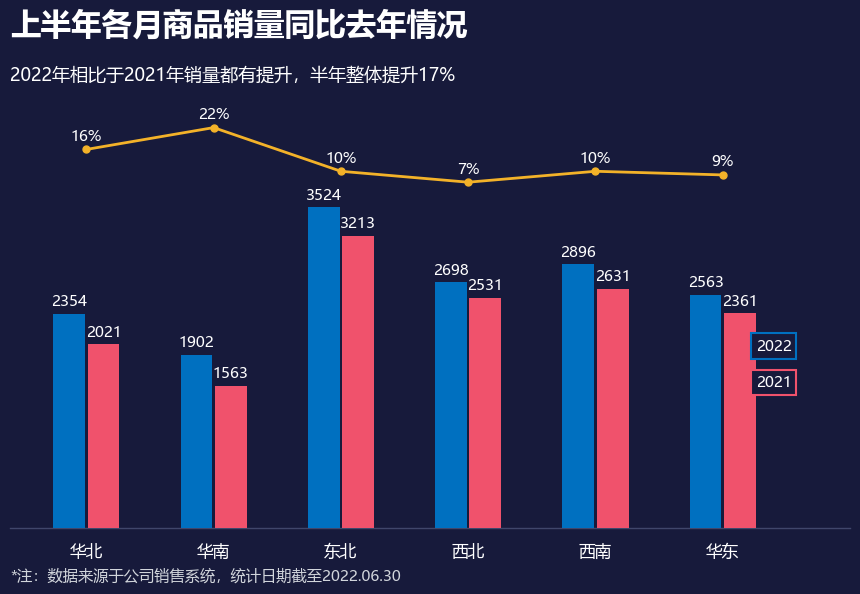

In [37]:
import matplotlib.pyplot as plt
import numpy as np

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 1. 准备数据（根据原图提取）
regions = ['华北', '华南', '东北', '西北', '西南', '华东']
sales_2022 = [2354, 1902, 3524, 2698, 2896, 2563]
sales_2021 = [2021, 1563, 3213, 2531, 2631, 2361]
yoy = [16, 22, 10, 7, 10, 9]  # 同比百分比

x = np.arange(len(regions))
width = 0.25  # 柱子较细，且两柱之间有微小间隙

# 2. 颜色配置
bg_color = '#171A3B'        # 深藏青背景
text_white = '#FFFFFF'      # 白色文字
text_light = '#D1D5DB'      # 浅灰文字
color_2022 = '#0070C0'      # 2022年蓝色
color_2021 = '#F0526C'      # 2021年红色
color_line = '#F3B229'      # 折线黄色
color_axis = '#40466B'      # 底部轴线颜色

# 3. 创建画布
fig, ax = plt.subplots(figsize=(10, 6.5))
fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)

# 4. 绘制双柱状图
# 左柱（2022），右柱（2021）
bars1 = ax.bar(x - width/2 - 0.01, sales_2022, width, color=color_2022, zorder=3)
bars2 = ax.bar(x + width/2 + 0.01, sales_2021, width, color=color_2021, zorder=3)

# 添加柱状图数据标签
for bar, val in zip(bars1, sales_2022):
    ax.text(bar.get_x() + bar.get_width()/2, val + 50, str(val), 
            ha='center', va='bottom', color=text_white, fontsize=11, zorder=4)
            
for bar, val in zip(bars2, sales_2021):
    ax.text(bar.get_x() + bar.get_width()/2, val + 50, str(val), 
            ha='center', va='bottom', color=text_white, fontsize=11, zorder=4)

# 5. ✅ 绘制折线图（将百分比映射到悬浮的视觉高度）
# 根据原图，折线最低点(7%)也远高于最高柱子(3524)，所以强行映射到 3800~4500 区间
min_yoy, max_yoy = 7, 22
base_y, height_scale = 3800, 600 
y_vis = [base_y + (val - min_yoy) / (max_yoy - min_yoy) * height_scale for val in yoy]

# 画折线与圆点
ax.plot(x, y_vis, color=color_line, linewidth=2, marker='o', markersize=5, zorder=5)

# 添加折线数据标签
for i, val in enumerate(yoy):
    ax.text(x[i], y_vis[i] + 60, f'{val}%', 
            ha='center', va='bottom', color=text_white, fontsize=11, zorder=6)

# 6. ✅ 绘制自定义图例（放在最后一组柱子的右侧上方）
legend_x = 5.4  # 靠近最后一个柱子的右边
legend_y1 = 2000 # 2022图例高度
legend_y2 = 1600 # 2021图例高度

# 2022图例（蓝框）
ax.text(legend_x, legend_y1, '2022', ha='center', va='center',
        color=text_white, fontsize=11,
        bbox=dict(boxstyle="square,pad=0.3", facecolor=bg_color, edgecolor=color_2022, linewidth=1.5), zorder=10)

# 2021图例（红框）
ax.text(legend_x, legend_y2, '2021', ha='center', va='center',
        color=text_white, fontsize=11,
        bbox=dict(boxstyle="square,pad=0.3", facecolor=bg_color, edgecolor=color_2021, linewidth=1.5), zorder=10)

# 7. 配置坐标轴
ax.set_xticks(x)
ax.set_xticklabels(regions, color=text_white, fontsize=12)
ax.tick_params(axis='x', length=0, pad=10)

# 隐藏Y轴刻度和边框
ax.set_yticks([])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)

# 保留底部轴线
ax.spines['bottom'].set_color(color_axis)
ax.spines['bottom'].set_linewidth(1)

# 设置 Y 轴范围
ax.set_ylim(0, 5000)
ax.set_xlim(-0.6, 6.0)  # X轴范围稍微拉宽一点，给图例留空间

# 8. 添加标题、副标题和底部注释
fig.text(0.08, 0.88, '上半年各月商品销量同比去年情况', color=text_white, fontsize=22, fontweight='bold')
fig.text(0.08, 0.81, '2022年相比于2021年销量都有提升，半年整体提升17%', color=text_white, fontsize=13)
fig.text(0.08, 0.04, '*注：数据来源于公司销售系统，统计日期截至2022.06.30', color=text_light, fontsize=11)

# 9. 调整布局
plt.subplots_adjust(top=0.82, bottom=0.12, left=0.08, right=0.92)
plt.show()

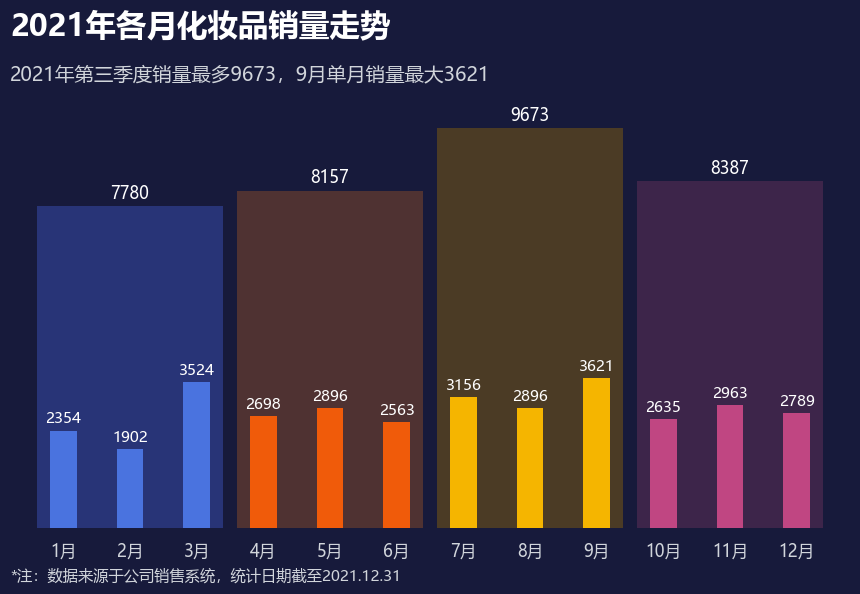

In [39]:
import matplotlib.pyplot as plt
import numpy as np

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 1. 准备数据
months = ['1月', '2月', '3月', '4月', '5月', '6月', '7月', '8月', '9月', '10月', '11月', '12月']
monthly_sales = [2354, 1902, 3524, 2698, 2896, 2563, 3156, 2896, 3621, 2635, 2963, 2789]
quarterly_sales = [7780, 8157, 9673, 8387]

x = np.arange(len(months))
x_q = [1, 4, 7, 10]  # 四个季度的中心点坐标

# 2. 颜色配置
bg_color = '#171A3B'        # 深藏青背景
text_white = '#FFFFFF'      # 白色文字
text_light = '#D1D5DB'      # 浅灰文字

# 季度大柱子的暗色系
color_q1 = '#283477' # 深蓝
color_q2 = '#4F3232' # 深棕
color_q3 = '#4B3B25' # 深橄榄
color_q4 = '#3D254A' # 深紫

# 月度小柱子的亮色系
color_m1 = '#4A73DF' # 亮蓝
color_m2 = '#F05B0A' # 橙色
color_m3 = '#F5B500' # 金黄
color_m4 = '#C04682' # 粉紫

# 3. 创建画布
fig, ax = plt.subplots(figsize=(10, 6.5))
fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)

# 4. ✅ 绘制底层大柱子（季度总销量）
width_q = 2.8
ax.bar(x_q[0], quarterly_sales[0], width=width_q, color=color_q1, zorder=2)
ax.bar(x_q[1], quarterly_sales[1], width=width_q, color=color_q2, zorder=2)
ax.bar(x_q[2], quarterly_sales[2], width=width_q, color=color_q3, zorder=2)
ax.bar(x_q[3], quarterly_sales[3], width=width_q, color=color_q4, zorder=2)

# 5. ✅ 绘制顶层小柱子（单月销量）
width_m = 0.4
for i in range(12):
    if i < 3: c = color_m1
    elif i < 6: c = color_m2
    elif i < 9: c = color_m3
    else: c = color_m4
    ax.bar(x[i], monthly_sales[i], width=width_m, color=c, zorder=3)

# 6. 添加数据标签
# 季度总销量标签
for i in range(4):
    ax.text(x_q[i], quarterly_sales[i] + 100, str(quarterly_sales[i]), 
            ha='center', va='bottom', color=text_white, fontsize=12, zorder=4)

# 单月销量标签
for i in range(12):
    ax.text(x[i], monthly_sales[i] + 100, str(monthly_sales[i]), 
            ha='center', va='bottom', color=text_white, fontsize=11, zorder=5)

# 7. 配置坐标轴
ax.set_xticks(x)
ax.set_xticklabels(months, color=text_light, fontsize=12)
ax.tick_params(axis='x', length=0, pad=10)

# 隐藏 Y 轴刻度和所有边框
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)

# 设置 Y 轴范围，给顶部标签留出空间
ax.set_ylim(0, 11000)
ax.set_xlim(-0.8, 11.8)

# 8. 添加标题、副标题和底部注释（严格左对齐）
fig.text(0.08, 0.88, '2021年各月化妆品销量走势', color=text_white, fontsize=22, fontweight='bold')
fig.text(0.08, 0.81, '2021年第三季度销量最多9673，9月单月销量最大3621', color=text_light, fontsize=14)
fig.text(0.08, 0.04, '*注：数据来源于公司销售系统，统计日期截至2021.12.31', color=text_light, fontsize=11)

# 9. 调整布局
plt.subplots_adjust(top=0.82, bottom=0.12, left=0.08, right=0.92)
plt.show()

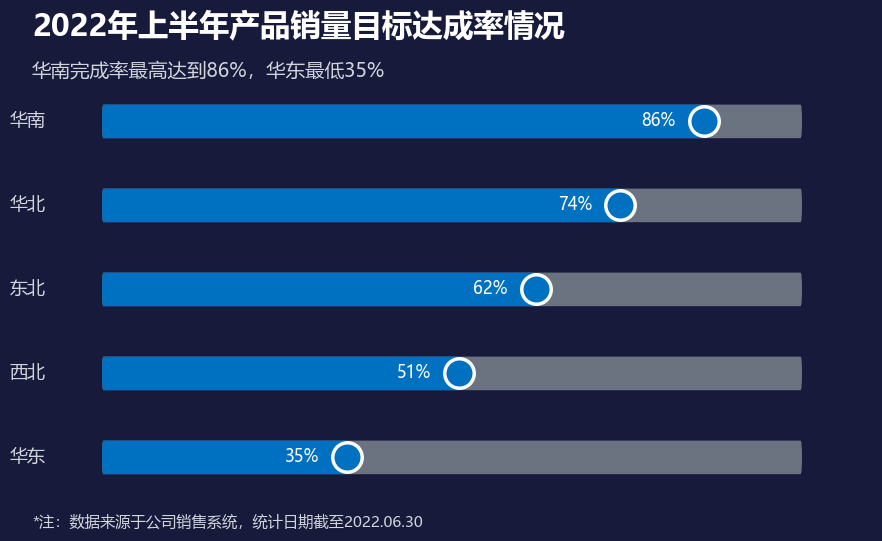

In [41]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 1. 准备数据（按原图从上到下：华南到华东）
regions = ['华南', '华北', '东北', '西北', '华东']
percentages = [86, 74, 62, 51, 35]

# 2. 颜色配置
bg_color = '#171A3B'          # 深藏青背景
text_white = '#FFFFFF'        # 白色文字
text_light = '#D1D5DB'        # 浅灰文字
color_bar_bg = '#6B7280'      # 进度条底色（灰色）
color_bar_fg = '#0070C0'      # 进度条前景（蓝色）
color_dot = '#0070C0'         # 滑块圆点颜色

# 3. 创建画布
fig, ax = plt.subplots(figsize=(10, 6))
fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)

# 4. 循环绘制每一条进度条
bar_height = 0.4        # 进度条高度
bar_max_width = 100     # 进度条最大宽度（对应100%）
y_positions = np.arange(len(regions))

for i in range(len(regions)):
    y = y_positions[i]
    pct = percentages[i]
    
    # 1. 绘制背景灰条（圆角矩形）
    bg_rect = patches.FancyBboxPatch(
        (0, y - bar_height/2), bar_max_width, bar_height,
        boxstyle=f"round,pad=0,rounding_size={bar_height/2}",
        facecolor=color_bar_bg, edgecolor='none', zorder=2
    )
    ax.add_patch(bg_rect)
    
    # 2. 绘制前景蓝条（圆角矩形）
    fg_rect = patches.FancyBboxPatch(
        (0, y - bar_height/2), pct, bar_height,
        boxstyle=f"round,pad=0,rounding_size={bar_height/2}",
        facecolor=color_bar_fg, edgecolor='none', zorder=3
    )
    ax.add_patch(fg_rect)
    
    # 3. 绘制末端的带白边滑块圆点
    ax.scatter(pct, y, s=450, color=color_dot, edgecolors=text_white, linewidth=2.5, zorder=5)
    
    # 4. 添加百分比文本（放在滑块左侧）
    ax.text(pct - 4, y, f'{pct}%', ha='right', va='center', 
            color=text_white, fontsize=12, zorder=6)
    
    # 5. 添加左侧区域标签
    ax.text(-8, y, regions[i], ha='right', va='center', 
            color=text_light, fontsize=13, zorder=6)

# 5. ✅ 核心修复：反转 Y 轴，让排名第一的数据显示在最上方
ax.invert_yaxis()

# 6. 配置坐标轴
ax.set_xlim(0, 110)
ax.set_ylim(len(regions) - 0.6, -0.6)  # 反转后的合理边界

# 隐藏所有边框和刻度
ax.set_xticks([])
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)

# 7. 添加标题、副标题和底部注释
fig.text(0.08, 0.88, '2022年上半年产品销量目标达成率情况', color=text_white, fontsize=22, fontweight='bold')
fig.text(0.08, 0.81, '华南完成率最高达到86%，华东最低35%', color=text_light, fontsize=14)
fig.text(0.08, 0.06, '*注：数据来源于公司销售系统，统计日期截至2022.06.30', color=text_light, fontsize=11)

# 8. 调整布局
plt.subplots_adjust(top=0.82, bottom=0.12, left=0.15, right=0.92)
plt.show()

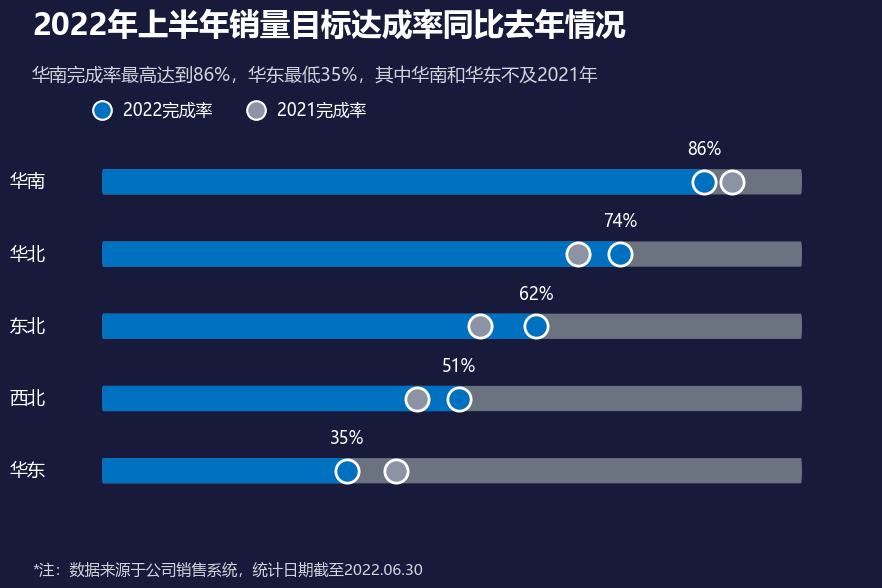

In [43]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 1. 准备数据（从上到下：华南到华东）
regions = ['华南', '华北', '东北', '西北', '华东']
pct_2022 = [86, 74, 62, 51, 35]
pct_2021 = [90, 68, 54, 45, 42] 

# 2. 颜色配置
bg_color = '#171A3B'          
text_white = '#FFFFFF'        
text_light = '#D1D5DB'        
color_bar_bg = '#6B7280'      
color_bar_fg = '#0070C0'      
color_dot_2022 = '#0070C0'    
color_dot_2021 = '#8B93A5'    

# 3. 创建画布
fig, ax = plt.subplots(figsize=(10, 6.5))
fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)

bar_height = 0.35
bar_max_width = 100
y_positions = np.arange(len(regions))

# 4. 循环绘制每一行
for i in range(len(regions)):
    y = y_positions[i]
    p22 = pct_2022[i]
    p21 = pct_2021[i]
    
    # 1. 背景灰槽
    bg_rect = patches.FancyBboxPatch(
        (0, y - bar_height/2), bar_max_width, bar_height,
        boxstyle=f"round,pad=0,rounding_size={bar_height/2}",
        facecolor=color_bar_bg, edgecolor='none', zorder=2
    )
    ax.add_patch(bg_rect)
    
    # 2. 前景蓝条
    fg_rect = patches.FancyBboxPatch(
        (0, y - bar_height/2), p22, bar_height,
        boxstyle=f"round,pad=0,rounding_size={bar_height/2}",
        facecolor=color_bar_fg, edgecolor='none', zorder=3
    )
    ax.add_patch(fg_rect)
    
    # 3. 2021 年灰点
    ax.scatter(p21, y, s=280, color=color_dot_2021, edgecolors=text_white, linewidth=2, zorder=4)
    
    # 4. 2022 年蓝点
    ax.scatter(p22, y, s=280, color=color_dot_2022, edgecolors=text_white, linewidth=2, zorder=5)
    
    # 5. ✅ 核心修复：百分比文本放在蓝点正上方（y 轴反转后，减号才是向上）
    ax.text(p22, y - 0.32, f'{p22}%', ha='center', va='bottom', 
            color=text_white, fontsize=12, zorder=6)
    
    # 6. 左侧区域标签
    ax.text(-8, y, regions[i], ha='right', va='center', 
            color=text_white, fontsize=13, zorder=6)

# 5. 绘制左上角的图例（同样因为 Y 轴反转，用负数坐标放在最顶上）
ax.scatter(0, -1.0, s=180, color=color_dot_2022, edgecolors=text_white, linewidth=1.5, clip_on=False)
ax.text(3, -1.0, '2022完成率', ha='left', va='center', color=text_white, fontsize=12)

ax.scatter(22, -1.0, s=180, color=color_dot_2021, edgecolors=text_white, linewidth=1.5, clip_on=False)
ax.text(25, -1.0, '2021完成率', ha='left', va='center', color=text_white, fontsize=12)

# 6. 反转 Y 轴
ax.invert_yaxis()

# 7. 配置坐标轴范围
ax.set_xlim(0, 110)
ax.set_ylim(len(regions) - 0.2, -1.5)  # 上方留出空间给图例

# 隐藏边框和刻度
ax.set_xticks([])
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)

# 8. 添加标题、副标题和底部注释
fig.text(0.08, 0.88, '2022年上半年销量目标达成率同比去年情况', color=text_white, fontsize=22, fontweight='bold')
fig.text(0.08, 0.81, '华南完成率最高达到86%，华东最低35%，其中华南和华东不及2021年', color=text_light, fontsize=13)
fig.text(0.08, 0.05, '*注：数据来源于公司销售系统，统计日期截至2022.06.30', color=text_light, fontsize=11)

# 9. 调整布局
plt.subplots_adjust(top=0.82, bottom=0.12, left=0.15, right=0.92)
plt.show()